# MAAI901 – Model Training and Evaluation

## Overview

This notebook contains the training and evaluation of seven deep learning models for skin lesion classification using the preprocessed ISIC 2019 and PAD-UFES-20 datasets.

We trained each model using two approaches: frozen backbone and full fine-tuning, giving us 14 experiments in total. The same training, validation and test splits were used for all models to keep the comparisons consistent.

The models used in this project are ResNet50, DenseNet121, MobileNetV2, MobileNetV3-Large, ViT-B/16, CLIP ViT-B/16 and DermLIP ViT-B/16.

## Training Approach

We used pretrained models and trained them using class-weighted cross-entropy loss to account for class imbalance. Each experiment was configured with a maximum of 15 epochs, early stopping and a fixed random seed for reproducibility.

We evaluated the models using accuracy, precision, recall, F1-score, balanced accuracy and ROC-AUC. We also compared the results of frozen-backbone training and full fine-tuning.

## Results and Further Evaluation

After training, we compared the performance of all seven models on the test dataset. We also carried out statistical analysis to calculate confidence intervals and compare model performance.

Finally, we tested the fine-tuned models on the external DDI dataset to examine how well they generalize to different clinical images and skin-tone groups. Additional analyses were performed to compare ISIC and PAD performance and investigate errors across different DDI diseases.

All model checkpoints, predictions, results and figures are saved in Google Drive under the `training/` folder.

## Cell 0 — Setup and configuration

In [ ]:
import os, sys, io, json, time, math, shutil, hashlib, subprocess, tarfile, warnings, random, traceback, datetime, gc
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
from PIL import Image, ImageOps
warnings.filterwarnings('ignore')


CONFIRM_RUN_TRAINING = False
ACK_DERMLIP_TERMS    = True
RUN_TEST_EVAL        = False
EXPERIMENTS_TO_RUN = 'ALL'
STOP_AFTER_MINUTES   = None
FROZEN_NAME          = 'frozen_v1'
SEED                 = 42
EPOCHS, PATIENCE, WARMUP_EPOCHS = 15, 4, 1
EFFECTIVE_BATCH      = 64
HEAD_LR, WEIGHT_DECAY, GRAD_CLIP = 1e-3, 1e-2, 1.0
IMG_CACHE, IMG_SIZE  = 256, 224
NUM_WORKERS          = 2
SAVE_CACHE_TAR       = True

TESTING = bool(os.environ.get('MAAI901_TEST'))
try:
    import google.colab  # noqa
    IN_COLAB = True
except Exception:
    IN_COLAB = False
if os.environ.get('MAAI901_BASE'):
    BASE = Path(os.environ['MAAI901_BASE'])
else:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/MAAI901_Group_Project')

def _pip(pkgs):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + pkgs)
def _have(mod):
    try:
        __import__(mod); return True
    except Exception:
        return False
if not TESTING:
    missing = [p for p, m in [('timm', 'timm'), ('open_clip_torch', 'open_clip'), ('scikit-learn', 'sklearn')] if not _have(m)]
    if missing:
        print('Installing', missing); _pip(missing)
HAS_TORCH = _have('torch')

PROCESSED  = BASE/'processed'
FROZEN     = PROCESSED/FROZEN_NAME
TRAIN_ROOT = BASE/'training'
EXP_ROOT   = TRAIN_ROOT/'experiments'
REPORTS    = TRAIN_ROOT/'reports'
CACHE_TAR_DIR = TRAIN_ROOT/'cache'
LOCAL_CACHE   = Path(os.environ.get('MAAI901_LOCAL', '/content/cache_img256'))
for p in [EXP_ROOT, REPORTS, CACHE_TAR_DIR, LOCAL_CACHE]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']
N_CLASSES = len(CLASSES)

class Halt(RuntimeError):
    pass
def halt(msg):
    raise Halt('\n\n[STOP] ' + msg)
def save_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, default=str)); os.replace(tmp, path)
def load_json(path, default=None):
    try: return json.loads(Path(path).read_text())
    except Exception: return default
def save_csv(df, path, **kw):
    path = Path(path); tmp = path.with_name(path.name + '.tmp'); df.to_csv(tmp, index=False, **kw); os.replace(tmp, path)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    if HAS_TORCH:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

print('Project folder :', BASE)
print('Frozen splits  :', FROZEN, '(exists)' if FROZEN.exists() else '(NOT FOUND)')
if HAS_TORCH:
    import torch
    print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())
    if torch.cuda.is_available():
        pr = torch.cuda.get_device_properties(0); print(f'GPU: {pr.name}, {pr.total_memory/1e9:.1f} GB')
    else:
        print('No GPU attached. Cells 0-3 and 5 (validation + image cache + matrix) run fine on CPU; attach a GPU (Runtime > Change runtime type > T4) before Cell 6.')
else:
    print('torch not importable here (training cells will refuse to run).')


Project folder : /content/drive/MyDrive/MAAI901_Group_Project
Frozen splits  : /content/drive/MyDrive/MAAI901_Group_Project/processed/frozen_v1 (exists)
torch 2.14.1+cpu | CUDA available: False
No GPU attached. Cells 0-3 and 5 (validation + image cache + matrix) run fine on CPU; attach a GPU (Runtime > Change runtime type > T4) before Cell 6.


## Cell 1 — Validate the frozen splits

In [ ]:
need = ['train.csv', 'val.csv', 'test.csv']
if not FROZEN.exists(): halt(f'{FROZEN} not found. Finish the freeze step in the preprocessing notebook first.')
absent = [n for n in need if not (FROZEN/n).is_file()]
if absent: halt(f'Missing frozen file(s): {absent}')

ck = load_json(FROZEN/'checksums.json', {}) or {}
for name, want in ck.items():
    f = FROZEN/name
    if f.exists() and hashlib.sha256(f.read_bytes()).hexdigest() != want:
        halt(f'{name} does not match checksums.json: the frozen file was modified after freezing.')
print(f'Checksums verified for {len([n for n in ck if (FROZEN/n).exists()])} frozen files.' if ck else 'No checksums.json found (cannot verify integrity).')

REQUIRED = ['image_uid', 'source_dataset', 'harmonized_label', 'label_idx', 'split', 'group_id', 'image_relpath']
dfs = {}
for s in ['train', 'val', 'test']:
    d = pd.read_csv(FROZEN/f'{s}.csv', dtype={'image_uid': str, 'group_id': str, 'image_relpath': str})
    miss = [c for c in REQUIRED if c not in d.columns]
    if miss: halt(f'{s}.csv lacks required columns {miss}. Columns present: {list(d.columns)}')
    if not (d.split == s).all(): halt(f'{s}.csv contains rows whose split column is not "{s}"')
    if d.image_uid.duplicated().any(): halt(f'{s}.csv has duplicated image_uid')
    if not d.harmonized_label.isin(CLASSES).all(): halt(f'{s}.csv has labels outside {CLASSES}')
    if not (d.label_idx.astype(int) == d.harmonized_label.map({c: i for i, c in enumerate(CLASSES)})).all(): halt(f'{s}.csv label_idx disagrees with class order {CLASSES}')
    if not d.source_dataset.isin(['ISIC2019', 'PAD_UFES_20']).all(): halt(f'{s}.csv contains a source other than ISIC2019/PAD_UFES_20 (DDI must never appear here)')
    d['label_idx'] = d.label_idx.astype(int); dfs[s] = d.reset_index(drop=True)

# Check for data leakage between splits
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    if set(dfs[a].image_uid) & set(dfs[b].image_uid): halt(f'image_uid overlap between {a} and {b}')
    if set(dfs[a].group_id) & set(dfs[b].group_id): halt(f'group_id overlap between {a} and {b}')
    if 'sha256' in dfs[a].columns and set(dfs[a].sha256.dropna()) & set(dfs[b].sha256.dropna()): halt(f'identical image files (sha256) appear in both {a} and {b}')
print('No overlap of image_uid / group_id / sha256 between splits.')

# Check confirmed duplicate images
for jf in FROZEN.glob('confirmed_duplicate*.json'):
    c = load_json(jf, {}); a, b = c.get('image_uid_a'), c.get('image_uid_b')
    allx = pd.concat(dfs.values()).set_index('image_uid')
    if a in allx.index and b in allx.index:
        same = allx.split[a] == allx.split[b]
        print(f'{jf.name}: {a} / {b} -> splits {allx.split[a]}/{allx.split[b]}, labels {allx.harmonized_label[a]}/{allx.harmonized_label[b]}')
        if not same: halt(f'{jf.name}: the confirmed duplicate pair sits in different splits. Regenerate the frozen splits.')
        if allx.harmonized_label[a] != allx.harmonized_label[b]:
            print('  WARNING: the confirmed duplicate pair has conflicting labels; the preprocessing policy would quarantine them. Decide and document before reporting.')
    else:
        print(f'{jf.name}: one or both images are not in the frozen splits (quarantined?) - OK.')

tot = sum(len(d) for d in dfs.values())
print(f'\nImages: train {len(dfs["train"]):,} | val {len(dfs["val"]):,} | test {len(dfs["test"]):,} | total {tot:,}' + ('' if tot == 27601 else '  (note: your preprocessing summary said 27,601)'))
dist = pd.concat({s: d.harmonized_label.value_counts().reindex(CLASSES, fill_value=0) for s, d in dfs.items()}, axis=1)
print(dist.to_string())
if (dist == 0).any().any(): halt('A class has zero images in a split.')
_all = pd.concat(dfs.values(), ignore_index=True)
print('Source by split:\n', pd.crosstab(_all.source_dataset, _all.split).to_string())

# Check that image files exist
for s, d in dfs.items():
    smp = d.image_relpath.sample(min(300, len(d)), random_state=0)
    bad = [p for p in smp if not (BASE/p).is_file()]
    if bad: halt(f'{len(bad)} of {len(smp)} sampled {s} images not found under {BASE} (e.g. {bad[0]}). Is the Drive folder mounted at the expected path?')
print('Sampled image paths resolve under the project folder.')

# Calculate class weights using training data
_cnt = dfs['train'].harmonized_label.value_counts().reindex(CLASSES).values.astype(float)
CLASS_WEIGHTS = (_cnt.sum() / (N_CLASSES * _cnt)).astype(np.float32)
print('Class weights (train only):', dict(zip(CLASSES, CLASS_WEIGHTS.round(3))))


Checksums verified for 4 frozen files.
No overlap of image_uid / group_id / sha256 between splits.
confirmed_duplicate_30.json: PAD_UFES_20:PAT_1694_3110_213.png / PAD_UFES_20:PAT_2161_4819_719.png -> splits train/train, labels NV/NV

Images: train 19,341 | val 4,131 | test 4,129 | total 27,601
                  train   val  test
harmonized_label                   
MEL                3352   610   610
NV                 8972  2071  2073
BCC                2999   580   578
AK                 1112   240   239
BKL                1993   433   433
DF                  167    36    36
VASC                177    38    38
SCC                 569   123   122
Source by split:
 split           test  train   val
source_dataset                   
ISIC2019        3788  17751  3788
PAD_UFES_20      341   1590   343
Sampled image paths resolve under the project folder.
Class weights (train only): {'MEL': np.float32(0.721), 'NV': np.float32(0.269), 'BCC': np.float32(0.806), 'AK': np.float32(2.174), 'BKL'

## Cell 2 — Resized-image cache

In [ ]:
def cache_name(uid):
    return uid.replace(':', '__').replace('/', '_') + '.jpg'

def _build_one(args):
    uid, rel = args
    dst = LOCAL_CACHE/cache_name(uid)
    if dst.exists() and dst.stat().st_size > 0: return None
    try:
        with Image.open(BASE/rel) as im:
            if im.format == 'JPEG':
                try: im.draft('RGB', (IMG_CACHE*2, IMG_CACHE*2))
                except Exception: pass
            im = ImageOps.exif_transpose(im).convert('RGB').resize((IMG_CACHE, IMG_CACHE), Image.BICUBIC)
        tmp = dst.with_name(dst.name + '.part'); im.save(tmp, 'JPEG', quality=95); os.replace(tmp, dst); return None
    except Exception as e:
        return (uid, f'{type(e).__name__}: {str(e)[:120]}')

ALL = pd.concat(dfs.values(), ignore_index=True)
tar_path = CACHE_TAR_DIR/f'images_{IMG_CACHE}.tar'
have = {p.name for p in LOCAL_CACHE.glob('*.jpg')}
need_uids = [u for u in ALL.image_uid if cache_name(u) not in have]
if need_uids and tar_path.exists():
    print(f'Restoring cache from {tar_path.name} ({len(have):,} local, {len(need_uids):,} missing) ...')
    with tarfile.open(tar_path) as tf: tf.extractall(LOCAL_CACHE)
    have = {p.name for p in LOCAL_CACHE.glob('*.jpg')}; need_uids = [u for u in ALL.image_uid if cache_name(u) not in have]
if need_uids:
    rel = dict(zip(ALL.image_uid, ALL.image_relpath)); jobs = [(u, rel[u]) for u in need_uids]
    print(f'Building {len(jobs):,} cached images from Drive (CPU, a one-off cost) ...'); t0 = time.time(); errs = []
    with ThreadPoolExecutor(8) as ex:
        for i, r in enumerate(ex.map(_build_one, jobs, chunksize=16)):
            if r: errs.append(r)
            if (i + 1) % 2000 == 0: print(f'  {i+1:,}/{len(jobs):,}  ({(time.time()-t0)/60:.1f} min)', flush=True)
    if errs:
        save_csv(pd.DataFrame(errs, columns=['image_uid', 'error']), REPORTS/'cache_errors.csv')
        halt(f'{len(errs)} images could not be cached (see training/reports/cache_errors.csv), e.g. {errs[0]}. Rerun this cell after fixing; finished images are kept.')
    have = {p.name for p in LOCAL_CACHE.glob('*.jpg')}; need_uids = [u for u in ALL.image_uid if cache_name(u) not in have]
if need_uids: halt(f'{len(need_uids)} cached images still missing.')
# Check a sample of cached images
for u in ALL.image_uid.sample(min(300, len(ALL)), random_state=1):
    with Image.open(LOCAL_CACHE/cache_name(u)) as im:
        im.load(); assert im.size == (IMG_CACHE, IMG_CACHE), f'bad cached image {u}'
print(f'Image cache OK: {len(ALL):,} images in {LOCAL_CACHE}')
if SAVE_CACHE_TAR and (not tar_path.exists() or (load_json(CACHE_TAR_DIR/'cache_manifest.json', {}) or {}).get('n') != len(ALL)):
    print('Writing cache tar to Drive (so a new session restores in minutes) ...'); tmp = tar_path.with_name(tar_path.name + '.tmp')
    with tarfile.open(tmp, 'w') as tf:
        for u in ALL.image_uid: tf.add(LOCAL_CACHE/cache_name(u), arcname=cache_name(u))
    os.replace(tmp, tar_path); save_json(CACHE_TAR_DIR/'cache_manifest.json', {'n': len(ALL), 'size': IMG_CACHE})
    print('  saved', tar_path, f'({tar_path.stat().st_size/1e9:.2f} GB)')


Restoring cache from images_256.tar (0 local, 27,601 missing) ...
Image cache OK: 27,601 images in /content/cache_img256


## Cell 3 — Experiment matrix, metrics, bookkeeping

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score)

ARCHS = {
 'resnet50':           dict(label='ResNet-50',         source='torchvision ResNet50_Weights.IMAGENET1K_V2',                   lr_ft=1e-4, bs_ft=64),
 'densenet121':        dict(label='DenseNet-121',      source='torchvision DenseNet121_Weights.IMAGENET1K_V1',                lr_ft=1e-4, bs_ft=32),
 'mobilenet_v2':       dict(label='MobileNetV2',       source='torchvision MobileNet_V2_Weights.IMAGENET1K_V2',               lr_ft=1e-4, bs_ft=64),
 'mobilenet_v3_large': dict(label='MobileNetV3-Large', source='torchvision MobileNet_V3_Large_Weights.IMAGENET1K_V2',        lr_ft=1e-4, bs_ft=64),
 'vit_b16':            dict(label='ViT-B/16',          source='timm vit_base_patch16_224.augreg_in21k_ft_in1k (Google AugReg)', lr_ft=2e-5, bs_ft=32),
 'clip_vit_b16':       dict(label='CLIP ViT-B/16',     source='open_clip ViT-B-16, pretrained=openai (OpenAI CLIP)',          lr_ft=1e-5, bs_ft=32),
 'dermlip_vit_b16':    dict(label='DermLIP ViT-B/16',  source='open_clip hf-hub:redlessone/DermLIP_ViT-B-16',                 lr_ft=1e-5, bs_ft=32),
}
MODES = ['frozen', 'finetune']

def make_matrix():
    rows = []
    for arch, a in ARCHS.items():
        for mode in MODES:
            bs = EFFECTIVE_BATCH if mode == 'frozen' else a['bs_ft']
            rows.append({'exp_id': f'{arch}__{mode}', 'arch': arch, 'model': a['label'], 'mode': mode, 'pretrained_source': a['source'],
                         'trainable': 'linear head only' if mode == 'frozen' else 'all weights',
                         'lr_backbone': 0.0 if mode == 'frozen' else a['lr_ft'], 'lr_head': HEAD_LR, 'batch': bs,
                         'grad_accum': EFFECTIVE_BATCH // bs, 'effective_batch': EFFECTIVE_BATCH, 'epochs_max': EPOCHS, 'patience': PATIENCE,
                         'optimizer': 'AdamW', 'schedule': f'{WARMUP_EPOCHS}-epoch warmup + cosine', 'loss': 'class-weighted CE', 'amp': 'fp16 if CUDA'})
    return pd.DataFrame(rows)
MATRIX = make_matrix()

def exp_dir(exp_id):
    d = EXP_ROOT/exp_id; d.mkdir(parents=True, exist_ok=True); return d
def read_status(exp_id):
    return load_json(exp_dir(exp_id)/'status.json', {'state': 'not_started'})
def write_status(exp_id, **kw):
    s = read_status(exp_id); s.update(kw); s['updated'] = time.strftime('%Y-%m-%d %H:%M:%S'); save_json(exp_dir(exp_id)/'status.json', s)
def is_complete(exp_id):
    d = exp_dir(exp_id)
    return read_status(exp_id).get('state') == 'completed' and (d/'best.pt').exists() and (d/'val_metrics.json').exists()
def selected_experiments():
    ids = list(MATRIX.exp_id) if EXPERIMENTS_TO_RUN == 'ALL' else list(EXPERIMENTS_TO_RUN)
    bad = [i for i in ids if i not in set(MATRIX.exp_id)]
    if bad: halt(f'Unknown experiment id(s) {bad}. Valid ids: {list(MATRIX.exp_id)}')
    return ids

def compute_metrics(y_true, probs, sources=None):
    y_true = np.asarray(y_true); probs = np.asarray(probs, dtype=np.float64); y_pred = probs.argmax(1); labels = list(range(N_CLASSES))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    auc = {}
    for c in labels:
        pos = int((y_true == c).sum())
        if 0 < pos < len(y_true): auc[CLASSES[c]] = float(roc_auc_score((y_true == c).astype(int), probs[:, c]))
    sup = {CLASSES[c]: int(s[c]) for c in labels}
    m = {'n': int(len(y_true)), 'accuracy': float(accuracy_score(y_true, y_pred)), 'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
         'macro_f1': float(f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)),
         'weighted_f1': float(f1_score(y_true, y_pred, labels=labels, average='weighted', zero_division=0)),
         'macro_precision': float(p.mean()), 'macro_recall': float(r.mean()),
         'per_class': {CLASSES[c]: {'precision': float(p[c]), 'recall': float(r[c]), 'f1': float(f[c]), 'support': int(s[c])} for c in labels},
         'confusion_matrix': cm.tolist(), 'roc_auc_per_class': auc}
    m['roc_auc_macro_ovr'] = float(np.mean(list(auc.values()))) if auc else None
    m['roc_auc_weighted_ovr'] = float(sum(auc[k] * sup[k] for k in auc) / sum(sup[k] for k in auc)) if auc else None
    mel = CLASSES.index('MEL'); tp = cm[mel, mel]; fn = cm[mel].sum() - tp; fp = cm[:, mel].sum() - tp; tn = cm.sum() - tp - fn - fp
    m['melanoma_recall'] = float(tp / (tp + fn)) if (tp + fn) else None
    m['melanoma_specificity'] = float(tn / (tn + fp)) if (tn + fp) else None
    if sources is not None:
        sources = np.asarray(sources); m['by_source'] = {}
        for sname in sorted(set(sources)):
            k = sources == sname
            m['by_source'][sname] = {'n': int(k.sum()), 'accuracy': float(accuracy_score(y_true[k], y_pred[k])),
                                     'macro_f1': float(f1_score(y_true[k], y_pred[k], labels=labels, average='macro', zero_division=0))}
    return m

def collect_results(split):
    rows = []
    for e in MATRIX.itertuples():
        m = load_json(EXP_ROOT/e.exp_id/f'{split}_metrics.json')
        if m is None: continue
        rows.append({'exp_id': e.exp_id, 'Model': e.model, 'Mode': 'Linear probe' if e.mode == 'frozen' else 'Full fine-tune',
                     'Accuracy': m['accuracy'], 'Balanced acc.': m['balanced_accuracy'], 'Macro-F1': m['macro_f1'], 'Weighted-F1': m['weighted_f1'],
                     'Macro ROC-AUC': m['roc_auc_macro_ovr'], 'MEL recall': m['melanoma_recall'], 'MEL specificity': m['melanoma_specificity'],
                     'Best epoch': (read_status(e.exp_id) or {}).get('best_epoch')})
    return pd.DataFrame(rows)

print(f'{len(MATRIX)} experiments defined. Completed so far:', sum(is_complete(i) for i in MATRIX.exp_id))


14 experiments defined. Completed so far: 14


## Cell 4 — Training engine

In [ ]:
if not HAS_TORCH: halt('torch is not importable in this runtime. Use a Colab GPU runtime.')
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision, torchvision.transforms as T
from torchvision.transforms import InterpolationMode

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
CKPT_EVERY_EPOCHS = 1                 # Save a checkpoint after every epoch
OPENAI_MEAN, OPENAI_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)

class ModelUnavailable(RuntimeError): pass
class SessionBudget(RuntimeError): pass

def build_backbone(arch):
    """Returns (feature_extractor producing (B, dim), dim, (mean, std), provenance). Never substitutes another model on failure."""
    import torchvision.models as tvm
    prov = {'arch': arch, 'source': ARCHS[arch]['source'], 'torch': torch.__version__, 'torchvision': torchvision.__version__}
    try:
        if arch == 'resnet50':
            w = tvm.ResNet50_Weights.IMAGENET1K_V2; m = tvm.resnet50(weights=w); dim = m.fc.in_features; m.fc = nn.Identity()
        elif arch == 'densenet121':
            w = tvm.DenseNet121_Weights.IMAGENET1K_V1; m = tvm.densenet121(weights=w); dim = m.classifier.in_features; m.classifier = nn.Identity()
        elif arch == 'mobilenet_v2':
            w = tvm.MobileNet_V2_Weights.IMAGENET1K_V2; m = tvm.mobilenet_v2(weights=w); dim = m.classifier[1].in_features; m.classifier = nn.Identity()
        elif arch == 'mobilenet_v3_large':
            w = tvm.MobileNet_V3_Large_Weights.IMAGENET1K_V2; m = tvm.mobilenet_v3_large(weights=w); dim = m.classifier[0].in_features; m.classifier = nn.Identity()
        elif arch == 'vit_b16':
            import timm
            m = timm.create_model('vit_base_patch16_224.augreg_in21k_ft_in1k', pretrained=True, num_classes=0)
            cfg = timm.data.resolve_data_config({}, model=m); dim = int(m.num_features); prov['timm'] = timm.__version__
            return m, dim, (tuple(cfg['mean']), tuple(cfg['std'])), prov
        elif arch in ('clip_vit_b16', 'dermlip_vit_b16'):
            import open_clip
            if arch == 'clip_vit_b16':
                model, _, pre = open_clip.create_model_and_transforms('ViT-B-16', pretrained='openai')
            else:
                model, _, pre = open_clip.create_model_and_transforms('hf-hub:redlessone/DermLIP_ViT-B-16')
            vis = model.visual; dim = int(vis.output_dim)
            isz = vis.image_size; isz = isz[0] if isinstance(isz, (tuple, list)) else isz
            if int(isz) != IMG_SIZE: raise ValueError(f'unexpected input size {isz}')
            nm = [t for t in pre.transforms if isinstance(t, T.Normalize)]
            ms = (tuple(nm[0].mean), tuple(nm[0].std)) if nm else (OPENAI_MEAN, OPENAI_STD)
            prov['open_clip'] = open_clip.__version__; del model; gc.collect()
            return vis, dim, ms, prov
        else:
            raise KeyError(arch)
        tr = w.transforms(); return m, int(dim), (tuple(tr.mean), tuple(tr.std)), prov
    except Exception as e:
        raise ModelUnavailable(f'{arch}: could not load the pretrained model ({type(e).__name__}: {str(e)[:300]}). '
                               'No substitute model is used; fix access/internet/package versions and rerun.') from e

class Net(nn.Module):
    def __init__(self, backbone, dim, n_classes, frozen):
        super().__init__()
        self.backbone, self.frozen = backbone, frozen
        self.head = nn.Linear(dim, n_classes); nn.init.normal_(self.head.weight, std=0.01); nn.init.zeros_(self.head.bias)
        if frozen:
            for p in self.backbone.parameters(): p.requires_grad = False
    def forward(self, x):
        if self.frozen:
            with torch.no_grad(): f = self.backbone(x)
        else:
            f = self.backbone(x)
        return self.head(f)

def set_mode(net, training):
    net.train(training)
    if net.frozen: net.backbone.eval()          # Keep the frozen backbone in evaluation mode

def make_transforms(mean, std, train):
    if train:
        return T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1), interpolation=InterpolationMode.BICUBIC, antialias=True),
                          T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomApply([T.RandomRotation(30)], p=0.5),
                          T.ColorJitter(0.2, 0.2, 0.2, 0.02), T.ToTensor(), T.Normalize(mean, std)])
    return T.Compose([T.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC, antialias=True), T.ToTensor(), T.Normalize(mean, std)])

class CacheDS(Dataset):
    def __init__(self, df, transform):
        self.paths = [str(LOCAL_CACHE/cache_name(u)) for u in df.image_uid]; self.y = df.label_idx.values.astype(int); self.t = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im: im = im.convert('RGB')
        except Exception as e:
            raise RuntimeError(f'cannot read cached image {self.paths[i]}: {e}. Rerun Cell 2 to rebuild/restore the cache.') from e
        return self.t(im), int(self.y[i])

def _seed_worker(_):
    s = torch.initial_seed() % 2**32; np.random.seed(s); random.seed(s)

def make_loader(df, norm, bs, train, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda', worker_init_fn=_seed_worker)
    if NUM_WORKERS > 0: kw.update(persistent_workers=True, prefetch_factor=4)
    return DataLoader(CacheDS(df, make_transforms(*norm, train)), batch_size=bs, shuffle=train, drop_last=train, generator=g, **kw)

def autocast_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP)
def make_scaler():
    try: return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)
def tload(path):
    try: return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError: return torch.load(path, map_location='cpu')
def tsave(obj, path):
    path = Path(path); tmp = path.with_name(path.name + '.tmp'); torch.save(obj, tmp); os.replace(tmp, path)
def cleanup_gpu():
    gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

@torch.no_grad()
def predict(net, loader):
    set_mode(net, False); probs, ys = [], []
    for x, y in loader:
        with autocast_ctx(): logits = net(x.to(DEVICE, non_blocking=True))
        probs.append(F.softmax(logits.float(), 1).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def weighted_nll(probs, y):
    w = CLASS_WEIGHTS[y]; return float((w * -np.log(probs[np.arange(len(y)), y] + 1e-12)).sum() / w.sum())

def build_net(exp_id):
    row = MATRIX.set_index('exp_id').loc[exp_id]; backbone, dim, norm, prov = build_backbone(row.arch)
    return Net(backbone, dim, N_CLASSES, frozen=(row['mode'] == 'frozen')).to(DEVICE), norm, prov, row

def _state(net): return net.head.state_dict() if net.frozen else net.state_dict()
def _load(net, st): (net.head if net.frozen else net).load_state_dict(st)

def run_experiment(exp_id, bs, deadline=None):
    d = exp_dir(exp_id); accum = max(1, EFFECTIVE_BATCH // bs)
    if DEVICE.type == 'cuda':
        free, total = torch.cuda.mem_get_info()
        if free < 3e9: raise RuntimeError(f'Only {free/1e9:.1f} GB GPU memory free. Restart the runtime (Runtime > Restart session) and rerun.')
    set_seed(SEED); net, norm, prov, row = build_net(exp_id); mode = row['mode']
    train_loader = make_loader(dfs['train'], norm, bs, True); val_loader = make_loader(dfs['val'], norm, 64, False)
    steps = len(train_loader) // accum; total_steps = EPOCHS * steps; warm = max(1, WARMUP_EPOCHS * steps)
    groups = [{'params': net.head.parameters(), 'lr': HEAD_LR}]
    if mode == 'finetune': groups.append({'params': net.backbone.parameters(), 'lr': float(row.lr_backbone)})
    opt = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    lam = lambda s: (s + 1) / warm if s < warm else 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total_steps - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=lam); scaler = make_scaler()
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, device=DEVICE))
    cfg = {'exp_id': exp_id, 'arch': row.arch, 'mode': mode, 'seed': SEED, 'effective_batch': EFFECTIVE_BATCH, 'epochs_max': EPOCHS,
           'patience': PATIENCE, 'batch': bs, 'grad_accum': accum, 'lr_backbone': float(row.lr_backbone), 'lr_head': HEAD_LR,
           'weight_decay': WEIGHT_DECAY, 'class_weights': dict(zip(CLASSES, CLASS_WEIGHTS.tolist())), 'norm_mean_std': norm,
           'provenance': prov, 'trainable_params': int(sum(p.numel() for p in net.parameters() if p.requires_grad)),
           'total_params': int(sum(p.numel() for p in net.parameters())), 'frozen_split_dir': str(FROZEN)}
    save_json(d/'config.json', cfg)
    hist, best, best_epoch, bad, start = [], -1.0, 0, 0, 1
    if (d/'last.pt').exists():
        ck = tload(d/'last.pt')
        if (ck.get('arch'), ck.get('mode'), ck.get('seed'), ck.get('effective_batch')) == (row.arch, mode, SEED, EFFECTIVE_BATCH):
            _load(net, ck['model']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
            hist, best, best_epoch, bad, start = ck['hist'], ck['best'], ck['best_epoch'], ck['bad'], ck['epoch'] + 1
            for _ in range((start - 1) * steps): sched.step()
            print(f'  resuming {exp_id} from epoch {start} (best so far {best:.4f} @ {best_epoch})')
        else:
            print('  last.pt does not match this configuration; starting from scratch.')
    write_status(exp_id, state='running', batch=bs, started=read_status(exp_id).get('started') or time.strftime('%Y-%m-%d %H:%M:%S'))
    stopped_early = bad >= PATIENCE
    for epoch in range(start, EPOCHS + 1):
        if stopped_early: break
        t0 = time.time(); set_mode(net, True); opt.zero_grad(set_to_none=True)
        train_loader.generator.manual_seed(SEED * 1000 + epoch); run_loss, nb = torch.zeros((), device=DEVICE), 0
        for i, (x, y) in enumerate(train_loader):
            x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
            with autocast_ctx(): logits = net(x)
            loss = criterion(logits.float(), y)
            if not bool(torch.isfinite(loss)): raise FloatingPointError(f'non-finite loss at epoch {epoch}, step {i}')
            scaler.scale(loss / accum).backward(); run_loss += loss.detach(); nb += 1
            if (i + 1) % accum == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_([p for p in net.parameters() if p.requires_grad], GRAD_CLIP)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        probs, yv = predict(net, val_loader); mv = compute_metrics(yv, probs)
        rec = {'epoch': epoch, 'train_loss': float(run_loss / max(nb, 1)), 'val_loss': weighted_nll(probs, yv), 'val_macro_f1': mv['macro_f1'],
               'val_accuracy': mv['accuracy'], 'val_balanced_acc': mv['balanced_accuracy'], 'lr_head': opt.param_groups[0]['lr'],
               'lr_backbone': opt.param_groups[-1]['lr'] if mode == 'finetune' else 0.0, 'seconds': round(time.time() - t0, 1), 'batch': bs}
        hist.append(rec)
        if mv['macro_f1'] > best + 1e-4:
            best, best_epoch, bad = mv['macro_f1'], epoch, 0
            tsave({'model': _state(net), 'epoch': epoch, 'val_macro_f1': best, 'arch': row.arch, 'mode': mode}, d/'best.pt')
        else:
            bad += 1
        save_csv(pd.DataFrame(hist), d/'history.csv')
        print(f'  [{exp_id}] ep {epoch:>2}/{EPOCHS}  train {rec["train_loss"]:.3f}  val_loss {rec["val_loss"]:.3f}  val macro-F1 {mv["macro_f1"]:.4f}  '
              f'bal-acc {mv["balanced_accuracy"]:.3f}  best {best:.4f}@{best_epoch}  ({rec["seconds"]:.0f}s)', flush=True)
        stopped_early = bad >= PATIENCE
        if epoch % CKPT_EVERY_EPOCHS == 0 or stopped_early or epoch == EPOCHS:
            tsave({'model': _state(net), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(), 'hist': hist, 'best': best, 'best_epoch': best_epoch,
                   'bad': bad, 'epoch': epoch, 'arch': row.arch, 'mode': mode, 'seed': SEED, 'effective_batch': EFFECTIVE_BATCH}, d/'last.pt')
        write_status(exp_id, state='running', epoch=epoch, best_epoch=best_epoch, best_val_macro_f1=best)
        if deadline and time.time() > deadline and epoch < EPOCHS and not stopped_early:
            write_status(exp_id, state='paused'); raise SessionBudget(f'time budget reached after epoch {epoch} of {exp_id}')
    # Evaluate using the best saved model
    _load(net, tload(d/'best.pt')['model']); probs, yv = predict(net, val_loader)
    mv = compute_metrics(yv, probs, sources=dfs['val'].source_dataset.values); save_json(d/'val_metrics.json', mv)
    pd.concat([dfs['val'][['image_uid', 'source_dataset']].reset_index(drop=True), pd.DataFrame({'y_true': yv, 'y_pred': probs.argmax(1)}),
               pd.DataFrame(probs, columns=[f'p_{c}' for c in CLASSES])], axis=1).to_csv(d/'val_preds.csv', index=False)
    write_status(exp_id, state='completed', epoch=len(hist), best_epoch=best_epoch, best_val_macro_f1=best, early_stopped=bool(stopped_early),
                 finished=time.strftime('%Y-%m-%d %H:%M:%S'))
    if (d/'last.pt').exists(): (d/'last.pt').unlink()          # Remove the temporary checkpoint after training
    del net, opt, scaler, train_loader, val_loader; cleanup_gpu()
    return mv

def run_with_oom_retry(exp_id, deadline=None):
    bs = read_status(exp_id).get('batch_override') or int(MATRIX.set_index('exp_id').loc[exp_id, 'batch'])
    for _ in range(4):
        try:
            return run_experiment(exp_id, bs, deadline)
        except torch.cuda.OutOfMemoryError:
            cleanup_gpu()
            if bs <= 8: raise
            bs //= 2; write_status(exp_id, batch_override=bs, note=f'GPU OOM: continuing with batch {bs} x accumulation {EFFECTIVE_BATCH // bs}')
            print(f'  GPU out of memory -> retrying {exp_id} with batch {bs} (gradient accumulation keeps the effective batch at {EFFECTIVE_BATCH})')
    raise RuntimeError('repeated GPU OOM')

def load_trained(exp_id):
    net, norm, prov, row = build_net(exp_id); _load(net, tload(exp_dir(exp_id)/'best.pt')['model']); return net, norm

def evaluate_split(exp_id, split):
    net, norm = load_trained(exp_id); df = dfs[split]; loader = make_loader(df, norm, 64, False)
    probs, y = predict(net, loader); m = compute_metrics(y, probs, sources=df.source_dataset.values)
    d = exp_dir(exp_id); save_json(d/f'{split}_metrics.json', m)
    pd.concat([df[['image_uid', 'source_dataset']].reset_index(drop=True), pd.DataFrame({'y_true': y, 'y_pred': probs.argmax(1)}),
               pd.DataFrame(probs, columns=[f'p_{c}' for c in CLASSES])], axis=1).to_csv(d/f'{split}_preds.csv', index=False)
    del net; cleanup_gpu(); return m
print('Engine ready on', DEVICE, '| AMP:', USE_AMP)


Engine ready on cuda | AMP: True


## Cell 5 — Experiment matrix and progress dashboard

In [ ]:
save_csv(MATRIX, TRAIN_ROOT/'experiment_matrix.csv')
show = MATRIX[['exp_id', 'model', 'mode', 'pretrained_source', 'lr_backbone', 'lr_head', 'batch', 'grad_accum', 'epochs_max']].copy()
show['state'] = [read_status(i).get('state', 'not_started') for i in show.exp_id]
show['best_epoch'] = [read_status(i).get('best_epoch') for i in show.exp_id]
show['best_val_macro_F1'] = [read_status(i).get('best_val_macro_f1') for i in show.exp_id]
print(show.to_string(index=False))
print(f'\nCompleted: {int((show.state == "completed").sum())}/14   (matrix saved to training/experiment_matrix.csv)')


                      exp_id             model     mode                                              pretrained_source  lr_backbone  lr_head  batch  grad_accum  epochs_max     state  best_epoch  best_val_macro_F1
            resnet50__frozen         ResNet-50   frozen                     torchvision ResNet50_Weights.IMAGENET1K_V2      0.00000    0.001     64           1          15 completed          14           0.432693
          resnet50__finetune         ResNet-50 finetune                     torchvision ResNet50_Weights.IMAGENET1K_V2      0.00010    0.001     64           1          15 completed          10           0.615455
         densenet121__frozen      DenseNet-121   frozen                  torchvision DenseNet121_Weights.IMAGENET1K_V1      0.00000    0.001     64           1          15 completed          14           0.412750
       densenet121__finetune      DenseNet-121 finetune                  torchvision DenseNet121_Weights.IMAGENET1K_V1      0.00010    0.001     32 

## Cell 6 — DermLIP notice + GPU smoke test

In [ ]:
print('DermLIP notice (read before setting ACK_DERMLIP_TERMS = True):')
print('  Model : huggingface.co/redlessone/DermLIP_ViT-B-16 (Hugging Face model card lists CC-BY-4.0).')
print('  Data  : it was pretrained on Derm1M, which is released CC BY-NC 4.0 (non-commercial research use).')
print('  Caution: Derm1M is assembled from web/educational sources; overlap with ISIC/PAD/DDI images cannot be ruled out by us.')
print('          Report DermLIP (and CLIP) results with this possible pretraining-data contamination stated.')
print('  Loading: open_clip.create_model_and_transforms("hf-hub:redlessone/DermLIP_ViT-B-16"). No substitute is used if it fails.\n')

if DEVICE.type != 'cuda': halt('The smoke test needs the GPU runtime (Runtime > Change runtime type > T4 GPU).')
rows = []
for arch, a in ARCHS.items():
    rec = {'arch': arch, 'ok': False, 'error': ''}
    try:
        if arch == 'dermlip_vit_b16' and not ACK_DERMLIP_TERMS:
            rec['error'] = 'skipped: set ACK_DERMLIP_TERMS = True in Cell 0 to include DermLIP'; rows.append(rec); continue
        cleanup_gpu(); torch.cuda.reset_peak_memory_stats(); set_seed(SEED)
        backbone, dim, norm, prov = build_backbone(arch)
        bs = a['bs_ft']; sub_tr = dfs['train'].sample(bs * 5, random_state=0); sub_va = dfs['val'].sample(64, random_state=0)
        trl = DataLoader(CacheDS(sub_tr, make_transforms(*norm, True)), batch_size=bs, shuffle=True, drop_last=True)
        val = DataLoader(CacheDS(sub_va, make_transforms(*norm, False)), batch_size=32)
        x, y = next(iter(trl)); x, y = x.to(DEVICE), y.to(DEVICE)
        assert x.shape == (bs, 3, IMG_SIZE, IMG_SIZE) and torch.isfinite(x).all(), 'bad input batch'
        # Test fine-tuning
        net = Net(backbone, dim, N_CLASSES, frozen=False).to(DEVICE); set_mode(net, True)
        opt = torch.optim.AdamW(net.parameters(), lr=1e-5); scaler = make_scaler(); crit = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, device=DEVICE))
        def step():
            with autocast_ctx(): out = net(x)
            assert out.shape == (bs, N_CLASSES), f'output {tuple(out.shape)}'
            loss = crit(out.float(), y); assert torch.isfinite(loss), 'non-finite loss'
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); return float(loss)
        l0 = step(); torch.cuda.synchronize(); t0 = time.time()
        for _ in range(3): step()
        torch.cuda.synchronize(); sps = (time.time() - t0) / 3
        rec['peak_mem_GB'] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
        steps_ep = len(dfs['train']) // bs; rec['ft_min_per_epoch_est'] = round(steps_ep * sps / 60, 1)
        # Test validation
        net.eval()
        with torch.no_grad(), autocast_ctx(): xv, yv = next(iter(val)); ov = net(xv.to(DEVICE))
        assert ov.shape == (xv.shape[0], N_CLASSES) and torch.isfinite(ov).all(), 'bad validation output'
        # Test frozen backbone
        fz = Net(net.backbone, dim, N_CLASSES, frozen=True).to(DEVICE); set_mode(fz, True)
        rec['trainable_frozen'] = int(sum(p.numel() for p in fz.parameters() if p.requires_grad)); assert rec['trainable_frozen'] == dim * N_CLASSES + N_CLASSES
        with torch.no_grad(), autocast_ctx(): fz(x)
        torch.cuda.synchronize(); t0 = time.time()
        with torch.no_grad(), autocast_ctx():
            for _ in range(3): fz(x)
        torch.cuda.synchronize(); rec['frozen_min_per_epoch_est'] = round(len(dfs['train']) // bs * (time.time() - t0) / 3 / 60, 1)
        rec.update(ok=True, feat_dim=dim, params_M=round(sum(p.numel() for p in net.backbone.parameters()) / 1e6, 1), batch=bs,
                   norm_mean=tuple(round(v, 3) for v in norm[0]), first_loss=round(l0, 3), weights=prov['source'])
        del net, fz, opt, scaler, backbone, x, y, xv; cleanup_gpu()
    except torch.cuda.OutOfMemoryError:
        rec['error'] = 'GPU OOM at the configured batch (training will auto-halve the batch and use gradient accumulation)'; cleanup_gpu()
    except ModelUnavailable as e:
        rec['error'] = str(e)[:260]; cleanup_gpu()
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {str(e)[:220]}'; cleanup_gpu()
    rows.append(rec); print(('PASS ' if rec['ok'] else 'FAIL ') + arch, rec.get('error', ''), flush=True)
smoke = pd.DataFrame(rows); save_csv(smoke, TRAIN_ROOT/'smoke_test_report.csv')
print(smoke.drop(columns=['weights'], errors='ignore').to_string(index=False))
print('\nEstimated minutes/epoch are measured on this GPU from 3 timed steps; multiply by up to', EPOCHS, 'epochs for a worst-case run time (early stopping usually shortens it).')
if not smoke.ok.all(): print('\nFix or knowingly exclude failing architectures (EXPERIMENTS_TO_RUN) before Cell 7. Nothing is substituted automatically.')


DermLIP notice (read before setting ACK_DERMLIP_TERMS = True):
  Model : huggingface.co/redlessone/DermLIP_ViT-B-16 (Hugging Face model card lists CC-BY-4.0).
  Data  : it was pretrained on Derm1M, which is released CC BY-NC 4.0 (non-commercial research use).
  Caution: Derm1M is assembled from web/educational sources; overlap with ISIC/PAD/DDI images cannot be ruled out by us.
          Report DermLIP (and CLIP) results with this possible pretraining-data contamination stated.
  Loading: open_clip.create_model_and_transforms("hf-hub:redlessone/DermLIP_ViT-B-16"). No substitute is used if it fails.

PASS resnet50 
PASS densenet121 
PASS mobilenet_v2 
PASS mobilenet_v3_large 
PASS vit_b16 
PASS clip_vit_b16 
PASS dermlip_vit_b16 
              arch   ok error  peak_mem_GB  ft_min_per_epoch_est  trainable_frozen  frozen_min_per_epoch_est  feat_dim  params_M  batch             norm_mean  first_loss
          resnet50 True               3.31                   0.8             16392         

## Cell 7 — Model Training

In [ ]:
if not CONFIRM_RUN_TRAINING: halt('Training is switched off. Set CONFIRM_RUN_TRAINING = True in Cell 0 (and rerun Cell 0), then run this cell.')
if DEVICE.type != 'cuda': halt('Training requires the GPU runtime.')
ids = selected_experiments()
if any(i.startswith('dermlip') for i in ids) and not ACK_DERMLIP_TERMS:
    print('DermLIP experiments are excluded because ACK_DERMLIP_TERMS is False.'); ids = [i for i in ids if not i.startswith('dermlip')]
deadline = time.time() + STOP_AFTER_MINUTES * 60 if STOP_AFTER_MINUTES else None
print('Planned:', ids); done = [i for i in ids if is_complete(i)]
print('Already completed (skipped):', done)
for exp_id in ids:
    if is_complete(exp_id): continue
    print(f'\n=== {exp_id} ===', flush=True); t0 = time.time()
    try:
        mv = run_with_oom_retry(exp_id, deadline)
        print(f'  done in {(time.time()-t0)/60:.1f} min | val macro-F1 {mv["macro_f1"]:.4f} | val balanced acc {mv["balanced_accuracy"]:.4f}')
    except SessionBudget as e:
        print('Stopping cleanly:', e, '\nRerun this cell later to resume.'); break
    except ModelUnavailable as e:
        write_status(exp_id, state='failed', error=str(e)); print('  FAILED (model unavailable):', e)
    except Exception as e:
        write_status(exp_id, state='failed', error=f'{type(e).__name__}: {e}'); print('  FAILED:', type(e).__name__, e); traceback.print_exc(); cleanup_gpu()
print('\nProgress:');
for i in ids: print(f'  {i:<34}', read_status(i).get('state'), '| best val macro-F1', read_status(i).get('best_val_macro_f1'))


Planned: ['dermlip_vit_b16__frozen', 'dermlip_vit_b16__finetune']
Already completed (skipped): []

=== dermlip_vit_b16__frozen ===
  [dermlip_vit_b16__frozen] ep  1/15  train 1.683  val_loss 1.298  val macro-F1 0.4356  bal-acc 0.495  best 0.4356@1  (88s)
  [dermlip_vit_b16__frozen] ep  2/15  train 1.173  val_loss 1.036  val macro-F1 0.5202  bal-acc 0.608  best 0.5202@2  (87s)
  [dermlip_vit_b16__frozen] ep  3/15  train 1.071  val_loss 0.976  val macro-F1 0.5192  bal-acc 0.615  best 0.5202@2  (88s)
  [dermlip_vit_b16__frozen] ep  4/15  train 1.026  val_loss 0.957  val macro-F1 0.5458  bal-acc 0.620  best 0.5458@4  (88s)
  [dermlip_vit_b16__frozen] ep  5/15  train 0.999  val_loss 0.904  val macro-F1 0.5360  bal-acc 0.647  best 0.5458@4  (88s)
  [dermlip_vit_b16__frozen] ep  6/15  train 0.986  val_loss 0.903  val macro-F1 0.5438  bal-acc 0.644  best 0.5458@4  (88s)
  [dermlip_vit_b16__frozen] ep  7/15  train 0.974  val_loss 0.915  val macro-F1 0.5565  bal-acc 0.638  best 0.5565@7  (87s)
 

## Cell 8 — Model Validation and Test Evaluation

In [ ]:
vl = collect_results('val')
if vl.empty: halt('No finished experiments yet (nothing to rank).')
vl = vl.sort_values('Macro-F1', ascending=False)
print('VALIDATION leaderboard (model selection uses this only):'); print(vl.drop(columns=['exp_id']).round(4).to_string(index=False))
save_csv(vl, REPORTS/'val_leaderboard.csv')
if not RUN_TEST_EVAL: halt('Test set untouched. After all training is complete and you have chosen what to report, set RUN_TEST_EVAL = True in Cell 0, rerun it, then rerun this cell.')
if DEVICE.type != 'cuda': halt('Evaluation needs the GPU runtime.')
ids = [i for i in selected_experiments() if is_complete(i)]
missing = [i for i in selected_experiments() if not is_complete(i)]
if missing: print('Not evaluated (training incomplete):', missing)
log = load_json(REPORTS/'test_eval_log.json', {}) or {}
for exp_id in ids:
    if (exp_dir(exp_id)/'test_metrics.json').exists(): print('  test already evaluated (kept, never recomputed):', exp_id); continue
    m = evaluate_split(exp_id, 'test'); log[exp_id] = time.strftime('%Y-%m-%d %H:%M:%S'); save_json(REPORTS/'test_eval_log.json', log)
    print(f'  {exp_id:<34} test macro-F1 {m["macro_f1"]:.4f} | bal-acc {m["balanced_accuracy"]:.4f} | MEL recall {m["melanoma_recall"]:.3f}')


VALIDATION leaderboard (model selection uses this only):
            Model           Mode  Accuracy  Balanced acc.  Macro-F1  Weighted-F1  Macro ROC-AUC  MEL recall  MEL specificity  Best epoch
 DermLIP ViT-B/16 Full fine-tune    0.7797         0.6949    0.6997       0.7810         0.9579      0.6197           0.9333           7
    CLIP ViT-B/16 Full fine-tune    0.7846         0.6750    0.6889       0.7702         0.9517      0.4016           0.9773           8
         ViT-B/16 Full fine-tune    0.7693         0.6532    0.6724       0.7570         0.9431      0.4016           0.9707           9
     DenseNet-121 Full fine-tune    0.7543         0.6395    0.6304       0.7405         0.9444      0.3590           0.9707          15
        ResNet-50 Full fine-tune    0.7463         0.6037    0.6155       0.7348         0.9299      0.3803           0.9719          10
MobileNetV3-Large Full fine-tune    0.7393         0.6143    0.6135       0.7331         0.9315      0.3836           0.9

## Cell 9 — Comparison tables and figures

Reporting split: TEST
            Model           Mode  Accuracy  Balanced acc.  Macro-F1  Weighted-F1  Macro ROC-AUC  MEL recall  MEL specificity  Best epoch
        ResNet-50   Linear probe    0.6350         0.5389    0.4430       0.6369         0.8877      0.2295           0.9696          14
        ResNet-50 Full fine-tune    0.7549         0.6202    0.6381       0.7423         0.9369      0.3885           0.9767          10
     DenseNet-121   Linear probe    0.5972         0.4995    0.4032       0.6110         0.8760      0.2459           0.9648          14
     DenseNet-121 Full fine-tune    0.7648         0.6523    0.6423       0.7529         0.9473      0.4115           0.9713          15
      MobileNetV2   Linear probe    0.6004         0.4749    0.3902       0.6097         0.8672      0.2180           0.9790          14
      MobileNetV2 Full fine-tune    0.7399         0.6413    0.6060       0.7280         0.9435      0.3311           0.9747          12
MobileNetV3-Large  

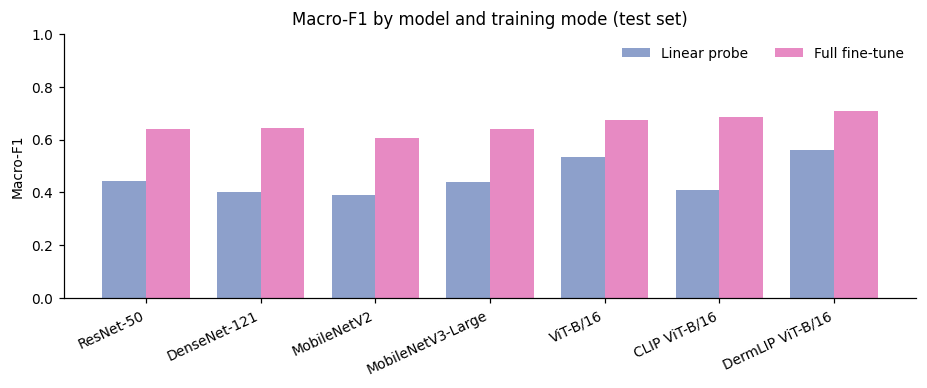

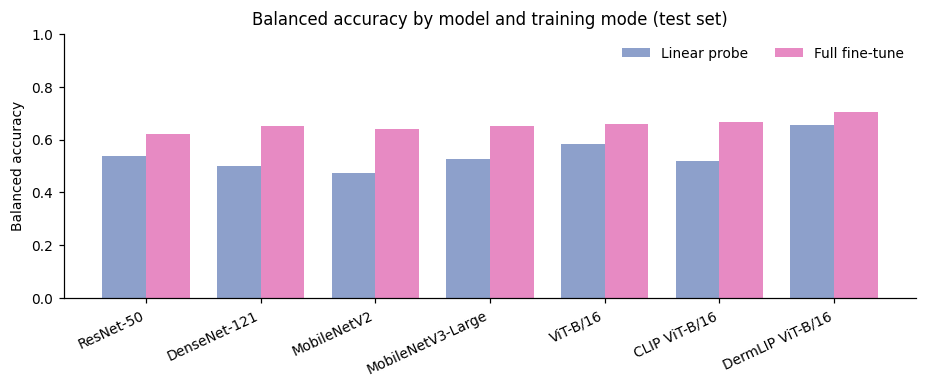

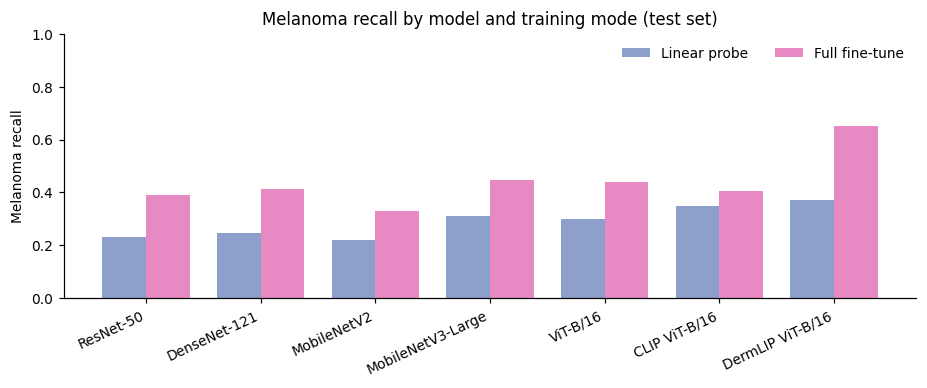

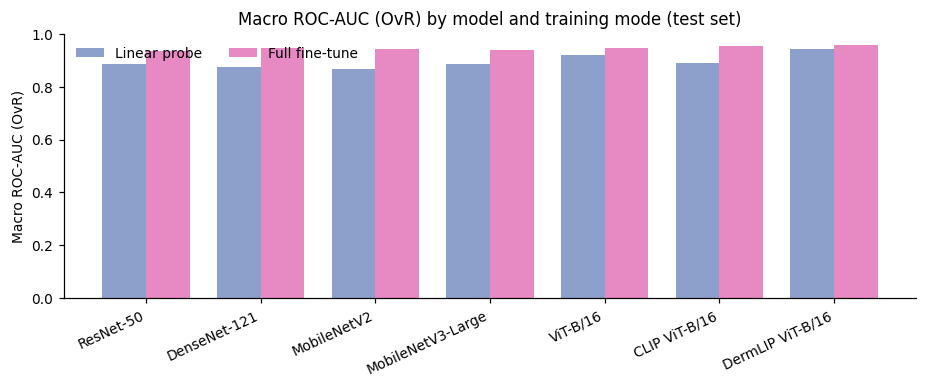

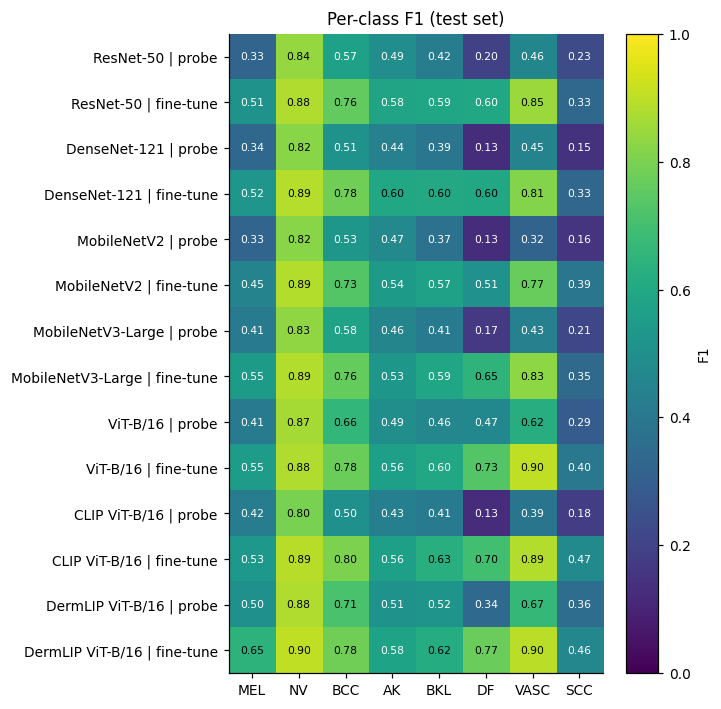

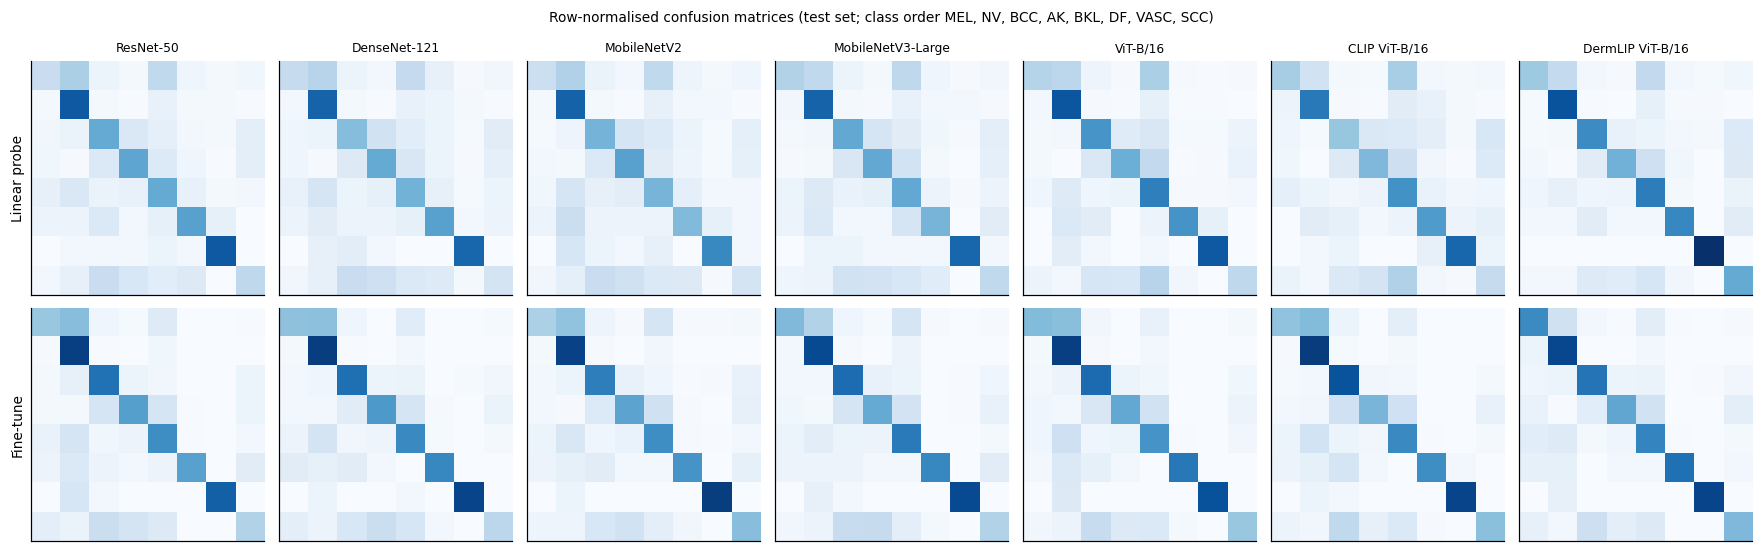

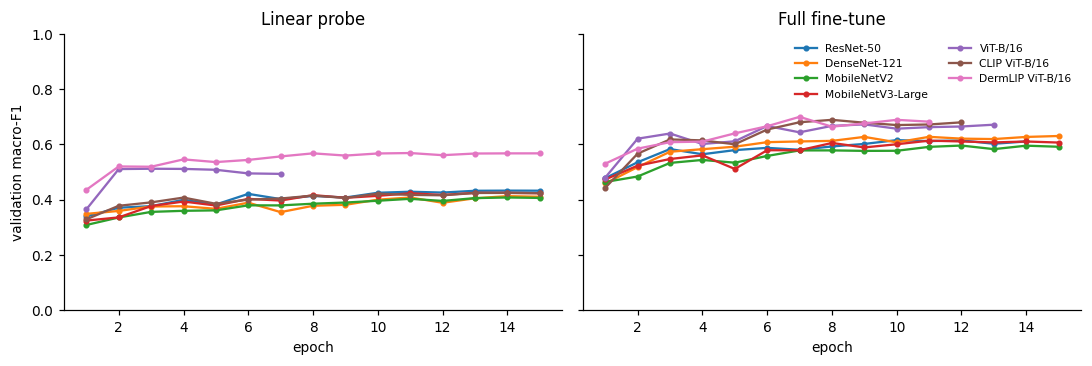

Saved to /content/drive/MyDrive/MAAI901_Group_Project/training/reports


In [ ]:
import matplotlib; import matplotlib.pyplot as plt
SPLIT_FOR_REPORT = 'test' if (RUN_TEST_EVAL and any((EXP_ROOT/i/'test_metrics.json').exists() for i in MATRIX.exp_id)) else 'val'
tab = collect_results(SPLIT_FOR_REPORT)
if tab.empty: halt('No finished experiments with saved metrics yet.')
FIG = REPORTS/f'figures_{SPLIT_FOR_REPORT}'; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
order = [a['label'] for a in ARCHS.values()]; modes = ['Linear probe', 'Full fine-tune']; colors = {'Linear probe': '#8da0cb', 'Full fine-tune': '#e78ac3'}
print(f'Reporting split: {SPLIT_FOR_REPORT.upper()}'); disp = tab.drop(columns=['exp_id']).round(4); print(disp.to_string(index=False))
save_csv(disp, REPORTS/f'comparison_table_{SPLIT_FOR_REPORT}.csv'); (REPORTS/f'comparison_table_{SPLIT_FOR_REPORT}.md').write_text(disp.to_markdown(index=False) if _have('tabulate') else disp.to_string(index=False))
(REPORTS/f'comparison_table_{SPLIT_FOR_REPORT}.tex').write_text(disp.to_latex(index=False, float_format='%.3f', na_rep='-'))

def grouped_bar(metric, ylabel, fname):
    fig, ax = plt.subplots(figsize=(8.5, 3.6)); w = 0.38
    for j, md in enumerate(modes):
        vals = [tab[(tab.Model == m) & (tab.Mode == md)][metric].mean() for m in order]
        ax.bar(np.arange(len(order)) + (j - 0.5) * w, vals, w, label=md, color=colors[md])
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha='right'); ax.set_ylabel(ylabel); ax.set_ylim(0, 1)
    ax.set_title(f'{ylabel} by model and training mode ({SPLIT_FOR_REPORT} set)'); ax.legend(frameon=False, ncol=2); fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(FIG/f'{fname}.{ext}', dpi=300)
    plt.show(); plt.close(fig)
for metric, yl, fn in [('Macro-F1', 'Macro-F1', 'macro_f1'), ('Balanced acc.', 'Balanced accuracy', 'balanced_accuracy'), ('MEL recall', 'Melanoma recall', 'melanoma_recall'),
                       ('Macro ROC-AUC', 'Macro ROC-AUC (OvR)', 'roc_auc')]:
    grouped_bar(metric, yl, fn)

# F1 scores for each class
rows_, lab_ = [], []
for e in MATRIX.itertuples():
    m = load_json(EXP_ROOT/e.exp_id/f'{SPLIT_FOR_REPORT}_metrics.json')
    if m: rows_.append([m['per_class'][c]['f1'] for c in CLASSES]); lab_.append(f'{e.model} | {"probe" if e.mode == "frozen" else "fine-tune"}')
if rows_:
    fig, ax = plt.subplots(figsize=(6.5, 0.38 * len(rows_) + 1.2)); im = ax.imshow(np.array(rows_), vmin=0, vmax=1, cmap='viridis', aspect='auto')
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(len(lab_))); ax.set_yticklabels(lab_)
    for i, r in enumerate(rows_):
        for j, v in enumerate(r): ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v < 0.6 else 'black', fontsize=7)
    fig.colorbar(im, ax=ax, label='F1'); ax.set_title(f'Per-class F1 ({SPLIT_FOR_REPORT} set)'); fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(FIG/f'per_class_f1_heatmap.{ext}', dpi=300)
    plt.show(); plt.close(fig)

# Confusion matrices for all models
fig, axes = plt.subplots(2, len(ARCHS), figsize=(2.3 * len(ARCHS), 5.2), squeeze=False)
for j, (arch, a) in enumerate(ARCHS.items()):
    for i, md in enumerate(MODES):
        ax = axes[i][j]; m = load_json(EXP_ROOT/f'{arch}__{md}'/f'{SPLIT_FOR_REPORT}_metrics.json'); ax.set_xticks([]); ax.set_yticks([])
        if not m: ax.text(0.5, 0.5, 'n/a', ha='center', va='center'); continue
        cm = np.array(m['confusion_matrix'], float); cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(cm, vmin=0, vmax=1, cmap='Blues')
        if i == 0: ax.set_title(a['label'], fontsize=8)
        if j == 0: ax.set_ylabel('Linear probe' if md == 'frozen' else 'Fine-tune')
fig.suptitle(f'Row-normalised confusion matrices ({SPLIT_FOR_REPORT} set; class order {", ".join(CLASSES)})', fontsize=9); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(FIG/f'confusion_matrices.{ext}', dpi=300)
plt.show(); plt.close(fig)

# Validation performance during training
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, md in zip(axes, MODES):
    for arch, a in ARCHS.items():
        h = EXP_ROOT/f'{arch}__{md}'/'history.csv'
        if h.exists(): hh = pd.read_csv(h); ax.plot(hh.epoch, hh.val_macro_f1, marker='o', ms=3, label=a['label'])
    ax.set_title('Linear probe' if md == 'frozen' else 'Full fine-tune'); ax.set_xlabel('epoch'); ax.set_ylim(0, 1)
axes[0].set_ylabel('validation macro-F1'); axes[1].legend(fontsize=7, frameon=False, ncol=2); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(FIG/f'learning_curves.{ext}', dpi=300)
plt.show(); plt.close(fig)
print('Saved to', REPORTS)


## Cell 10 — Statistical Analysis

Integrity check passed for 14 experiments (recomputed macro-F1, balanced accuracy, MEL recall and MEL AUC equal the saved test_metrics.json).
3,681 test groups; 2000 group-bootstrap replicates (shared across models => paired).

TEST metrics with 95% group-bootstrap CI:
metric                              balanced_acc              macro_f1               mel_auc
model             mode                                                                      
CLIP ViT-B/16     finetune  0.665 [0.630, 0.700]  0.684 [0.652, 0.713]  0.903 [0.888, 0.919]
                  frozen    0.519 [0.486, 0.552]  0.408 [0.387, 0.430]  0.808 [0.789, 0.829]
DenseNet-121      finetune  0.652 [0.621, 0.682]  0.642 [0.612, 0.670]  0.889 [0.872, 0.906]
                  frozen    0.499 [0.465, 0.533]  0.403 [0.379, 0.426]  0.803 [0.784, 0.823]
DermLIP ViT-B/16  finetune  0.703 [0.673, 0.734]  0.708 [0.679, 0.733]  0.920 [0.907, 0.932]
                  frozen    0.656 [0.625, 0.687]  0.562 [0.534, 0.588]  0.890 [

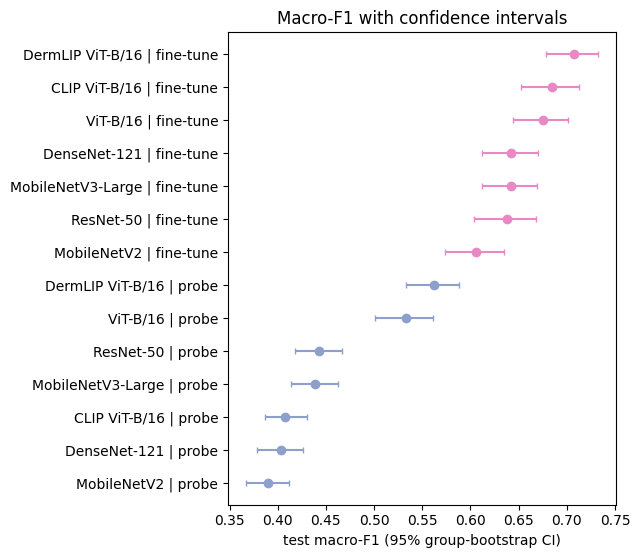

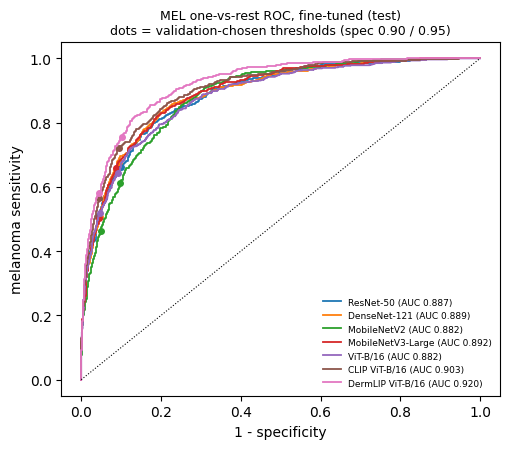

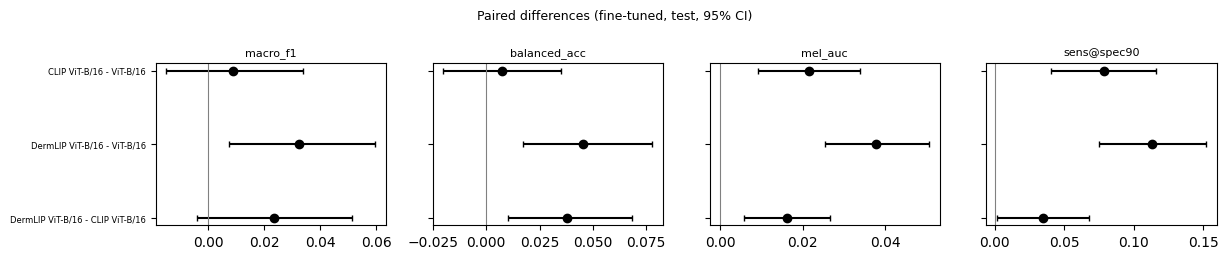


Saved to /content/drive/MyDrive/MAAI901_Group_Project/training/reports/analysis 
 ['bootstrap_ci_test.csv', 'macro_f1_forest.pdf', 'macro_f1_forest.png', 'mel_auc_ci_test.csv', 'mel_operating_points.csv', 'mel_roc_fine_tuned.pdf', 'mel_roc_fine_tuned.png', 'paired_comparisons_test.csv', 'paired_differences.pdf', 'paired_differences.png']


In [ ]:
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
B = 2000                       # Number of bootstrap samples
TARGET_SPECS = [0.90, 0.95]    # Specificity levels for melanoma
OUT = REPORTS/'analysis'; OUT.mkdir(parents=True, exist_ok=True)
SC = [f'p_{c}' for c in CLASSES]

def load_preds(exp_id, split):
    p = EXP_ROOT/exp_id/f'{split}_preds.csv'
    if not p.exists(): return None
    d = pd.read_csv(p).set_index('image_uid').reindex(dfs[split].image_uid)
    assert d.y_true.notna().all(), f'{exp_id}/{split}: predictions do not cover the whole split'
    assert (d.y_true.astype(int).values == dfs[split].label_idx.values).all(), f'{exp_id}/{split}: labels disagree with the frozen split'
    return d[SC].values.astype(np.float64)

ids = [i for i in MATRIX.exp_id if (EXP_ROOT/i/'test_preds.csv').exists() and (EXP_ROOT/i/'val_preds.csv').exists()]
skipped = [i for i in MATRIX.exp_id if i not in ids]
if skipped: print('No saved predictions (skipped):', skipped)
if not ids: halt('No experiment has both val_preds.csv and test_preds.csv yet.')
PV, PT = {i: load_preds(i, 'val') for i in ids}, {i: load_preds(i, 'test') for i in ids}
yv, yt = dfs['val'].label_idx.values, dfs['test'].label_idx.values
PRED = {i: PT[i].argmax(1) for i in ids}; MELS = {i: PT[i][:, 0] for i in ids}       # MEL = class 0

def cm_of(y, pred): return np.bincount(y * N_CLASSES + pred, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
def cm_stats(cm):
    tp = np.diag(cm).astype(float); sup = cm.sum(1); pp = cm.sum(0)
    prec = np.divide(tp, pp, out=np.zeros(len(tp)), where=pp > 0); rec = np.divide(tp, sup, out=np.zeros(len(tp)), where=sup > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(len(tp)), where=(prec + rec) > 0)
    return f1.mean(), rec[sup > 0].mean(), rec[0]                              # Calculate F1, balanced accuracy and melanoma recall
def mel_auc(y, s):
    pos = y == 0; n1 = int(pos.sum()); n0 = len(y) - n1
    return (rankdata(s)[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def sens_spec(y, s, thr):
    pos = y == 0; return float((s[pos] > thr).mean()), float((s[~pos] <= thr).mean())

# Check calculated metrics against saved results
for i in ids:
    m = load_json(EXP_ROOT/i/'test_metrics.json')
    if m:
        f1_, ba_, mr_ = cm_stats(cm_of(yt, PRED[i]))
        assert abs(f1_ - m['macro_f1']) < 1e-6 and abs(ba_ - m['balanced_accuracy']) < 1e-6 and abs(mr_ - m['melanoma_recall']) < 1e-6, f'{i}: recomputed metrics differ from saved test_metrics.json'
        assert abs(mel_auc(yt, MELS[i]) - m['roc_auc_per_class']['MEL']) < 1e-6, f'{i}: MEL AUC differs from saved value'
print(f'Integrity check passed for {len(ids)} experiments (recomputed macro-F1, balanced accuracy, MEL recall and MEL AUC equal the saved test_metrics.json).')

# Calculate melanoma thresholds from validation data
THR = {}
for i in ids:
    neg = PV[i][:, 0][yv != 0]
    for t in TARGET_SPECS: THR[(i, t)] = float(np.quantile(neg, t))

# Resample groups for confidence intervals
gcode, guniq = pd.factorize(dfs['test'].group_id); order = np.argsort(gcode, kind='stable')
members = np.split(order, np.cumsum(np.bincount(gcode))[:-1]); G = len(members); rng = np.random.default_rng(SEED)
boot = [np.concatenate([members[k] for k in rng.integers(0, G, G)]) for _ in range(B)]
print(f'{G:,} test groups; {B} group-bootstrap replicates (shared across models => paired).')

KEYS = ['macro_f1', 'balanced_acc', 'mel_recall', 'mel_auc'] + [f'sens@spec{int(t*100)}' for t in TARGET_SPECS] + [f'spec@spec{int(t*100)}' for t in TARGET_SPECS]
R = {i: {k: np.empty(B) for k in KEYS} for i in ids}
for i in ids:
    for b, idx in enumerate(boot):
        yy, pp, ss = yt[idx], PRED[i][idx], MELS[i][idx]; f1_, ba_, mr_ = cm_stats(cm_of(yy, pp))
        R[i]['macro_f1'][b], R[i]['balanced_acc'][b], R[i]['mel_recall'][b], R[i]['mel_auc'][b] = f1_, ba_, mr_, mel_auc(yy, ss)
        for t in TARGET_SPECS:
            se, sp = sens_spec(yy, ss, THR[(i, t)]); R[i][f'sens@spec{int(t*100)}'][b] = se; R[i][f'spec@spec{int(t*100)}'][b] = sp
def point(i):
    f1_, ba_, mr_ = cm_stats(cm_of(yt, PRED[i])); d = {'macro_f1': f1_, 'balanced_acc': ba_, 'mel_recall': mr_, 'mel_auc': mel_auc(yt, MELS[i])}
    for t in TARGET_SPECS: d[f'sens@spec{int(t*100)}'], d[f'spec@spec{int(t*100)}'] = sens_spec(yt, MELS[i], THR[(i, t)])
    return d
lab = MATRIX.set_index('exp_id')
rows = []
for i in ids:
    pt = point(i)
    for k in KEYS: rows.append({'exp_id': i, 'model': lab.model[i], 'mode': lab['mode'][i], 'metric': k, 'estimate': pt[k], 'ci_lo': np.percentile(R[i][k], 2.5), 'ci_hi': np.percentile(R[i][k], 97.5)})
CI = pd.DataFrame(rows); save_csv(CI, OUT/'bootstrap_ci_test.csv')
show = CI[CI.metric.isin(['macro_f1', 'balanced_acc', 'mel_auc'])].copy()
show['value'] = show.apply(lambda r: f'{r.estimate:.3f} [{r.ci_lo:.3f}, {r.ci_hi:.3f}]', axis=1)
print('\nTEST metrics with 95% group-bootstrap CI:'); print(show.pivot_table(index=['model', 'mode'], columns='metric', values='value', aggfunc='first').to_string())

# Evaluate melanoma sensitivity and specificity
op = []
for i in ids:
    pt = point(i)
    for t in TARGET_SPECS:
        k = int(t * 100); vs, vp = sens_spec(yv, PV[i][:, 0], THR[(i, t)])
        op.append({'exp_id': i, 'model': lab.model[i], 'mode': lab['mode'][i], 'target_specificity': t, 'val_threshold_on_p_MEL': THR[(i, t)], 'val_sensitivity': vs, 'val_specificity': vp,
                   'test_sensitivity': pt[f'sens@spec{k}'], 'test_sens_lo': np.percentile(R[i][f'sens@spec{k}'], 2.5), 'test_sens_hi': np.percentile(R[i][f'sens@spec{k}'], 97.5),
                   'test_specificity': pt[f'spec@spec{k}'], 'test_spec_lo': np.percentile(R[i][f'spec@spec{k}'], 2.5), 'test_spec_hi': np.percentile(R[i][f'spec@spec{k}'], 97.5)})
OP = pd.DataFrame(op); save_csv(OP, OUT/'mel_operating_points.csv')
print('\nMELANOMA sensitivity at validation-chosen thresholds (test; achieved specificity shown because it can drift from the target):')
print(OP[OP['mode'] == 'finetune'].round(3)[['model', 'target_specificity', 'val_sensitivity', 'test_sensitivity', 'test_sens_lo', 'test_sens_hi', 'test_specificity']].to_string(index=False))

# Compare model performance using paired samples
def holm(p):
    o = np.argsort(p); adj = np.empty(len(p)); run = 0
    for r, j in enumerate(o): run = max(run, (len(p) - r) * p[j]); adj[j] = min(1.0, run)
    return adj
PAIRS = [('dermlip_vit_b16', 'clip_vit_b16'), ('dermlip_vit_b16', 'vit_b16'), ('clip_vit_b16', 'vit_b16')]; pr = []
for mode in ['finetune', 'frozen']:
    for k in KEYS[:4] + [f'sens@spec{int(t*100)}' for t in TARGET_SPECS]:
        ps = []
        for a, b in PAIRS:
            ea, eb = f'{a}__{mode}', f'{b}__{mode}'
            if ea not in ids or eb not in ids: continue
            d = R[ea][k] - R[eb][k]; est = point(ea)[k] - point(eb)[k]
            p = min(1.0, 2 * min(((d <= 0).sum() + 1) / (B + 1), ((d >= 0).sum() + 1) / (B + 1)))
            ps.append(len(pr)); pr.append({'mode': mode, 'metric': k, 'A': lab.model[ea], 'B': lab.model[eb], 'diff_A_minus_B': est, 'ci_lo': np.percentile(d, 2.5), 'ci_hi': np.percentile(d, 97.5), 'p_bootstrap': p})
        if ps:
            adj = holm(np.array([pr[j]['p_bootstrap'] for j in ps]))
            for j, a_ in zip(ps, adj): pr[j]['p_holm_3_comparisons'] = a_
PC = pd.DataFrame(pr); PC['significant_at_0.05_holm'] = PC.p_holm_3_comparisons < 0.05; save_csv(PC, OUT/'paired_comparisons_test.csv')
print('\nPAIRED comparisons, full fine-tuning (A minus B; Holm-adjusted over the 3 pairs per metric):')
print(PC[PC['mode'] == 'finetune'].round(4)[['metric', 'A', 'B', 'diff_A_minus_B', 'ci_lo', 'ci_hi', 'p_holm_3_comparisons', 'significant_at_0.05_holm']].to_string(index=False))

# Save melanoma AUC results
save_csv(CI[CI.metric == 'mel_auc'][['model', 'mode', 'estimate', 'ci_lo', 'ci_hi']].rename(columns={'estimate': 'mel_auc'}), OUT/'mel_auc_ci_test.csv')

# Plot results
colors = {'finetune': '#e78ac3', 'frozen': '#8da0cb'}
f1 = CI[CI.metric == 'macro_f1'].sort_values('estimate'); fig, ax = plt.subplots(figsize=(6.5, 0.32 * len(f1) + 1.2))
for y_, r in enumerate(f1.itertuples()):
    ax.errorbar(r.estimate, y_, xerr=[[r.estimate - r.ci_lo], [r.ci_hi - r.estimate]], fmt='o', color=colors[r.mode], capsize=2)
ax.set_yticks(range(len(f1))); ax.set_yticklabels([f'{r.model} | {"probe" if r.mode == "frozen" else "fine-tune"}' for r in f1.itertuples()]); ax.set_xlabel('test macro-F1 (95% group-bootstrap CI)')
ax.set_title('Macro-F1 with confidence intervals'); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUT/f'macro_f1_forest.{ext}', dpi=300)
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for a in ARCHS:
    e = f'{a}__finetune'
    if e not in ids: continue
    fpr, tpr, _ = roc_curve((yt == 0).astype(int), MELS[e]); l, = ax.plot(fpr, tpr, lw=1.3, label=f'{lab.model[e]} (AUC {point(e)["mel_auc"]:.3f})')
    for t in TARGET_SPECS:
        se, sp = sens_spec(yt, MELS[e], THR[(e, t)]); ax.plot(1 - sp, se, 'o', ms=4, color=l.get_color())
ax.plot([0, 1], [0, 1], 'k:', lw=0.8); ax.set_xlabel('1 - specificity'); ax.set_ylabel('melanoma sensitivity'); ax.set_title('MEL one-vs-rest ROC, fine-tuned (test)\ndots = validation-chosen thresholds (spec 0.90 / 0.95)', fontsize=9)
ax.legend(fontsize=6.5, frameon=False, loc='lower right'); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUT/f'mel_roc_fine_tuned.{ext}', dpi=300)
plt.show(); plt.close(fig)

sub = PC[PC['mode'] == 'finetune']
if len(sub):
    mets = ['macro_f1', 'balanced_acc', 'mel_auc', 'sens@spec90']; fig, axes = plt.subplots(1, len(mets), figsize=(3.1 * len(mets), 2.6), sharey=True)
    for ax, k in zip(axes, mets):
        s = sub[sub.metric == k].reset_index(drop=True)
        for y_, r in s.iterrows(): ax.errorbar(r.diff_A_minus_B, y_, xerr=[[r.diff_A_minus_B - r.ci_lo], [r.ci_hi - r.diff_A_minus_B]], fmt='o', color='k', capsize=2)
        ax.axvline(0, color='grey', lw=0.8); ax.set_title(k, fontsize=8); ax.set_yticks(range(len(s))); ax.set_yticklabels([f'{r.A} - {r.B}' for r in s.itertuples()], fontsize=6)
    fig.suptitle('Paired differences (fine-tuned, test, 95% CI)', fontsize=9); fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(OUT/f'paired_differences.{ext}', dpi=300)
    plt.show(); plt.close(fig)
print('\nSaved to', OUT, '\n', sorted(p.name for p in OUT.iterdir()))

## DDI Dataset — File and Metadata Verification

In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

D = Path('/content/drive/MyDrive/MAAI901_Group_Project/datasets/DDI_PRIVATE/raw')

print("Files:", [p.name for p in D.iterdir()])

with zipfile.ZipFile(D / 'Files_files.zip') as z:
    names = z.namelist()
    print("ZIP entries:", len(names))
    print("First 10:", names[:10])
    print("PNG images:", sum(n.lower().endswith('.png') for n in names))

m = pd.read_csv(D / 'ddi_metadata.csv')
print("Metadata shape:", m.shape)
print("Columns:", m.columns.tolist())
print(m.head(3).to_string(index=False))

Files: ['files.csv', 'ddi_metadata.csv', 'Files_files.zip']
ZIP entries: 1316
First 10: ['Files_files/', '__MACOSX/._Files_files', 'Files_files/000387.png', '__MACOSX/Files_files/._000387.png', 'Files_files/000393.png', '__MACOSX/Files_files/._000393.png', 'Files_files/000378.png', '__MACOSX/Files_files/._000378.png', 'Files_files/000422.png', '__MACOSX/Files_files/._000422.png']
PNG images: 1312
Metadata shape: (656, 6)
Columns: ['_unnamed_var', 'DDI_ID', 'DDI_file', 'skin_tone', 'malignant', 'disease']
 _unnamed_var  DDI_ID   DDI_file  skin_tone  malignant           disease
          313     314 000314.png         12      False       acrochordon
          263     264 000264.png         12      False actinic-keratosis
          402     403 000403.png         12      False           angioma


## DDI Dataset — Image Extraction and Verification

In [ ]:
from pathlib import Path
import zipfile
import pandas as pd
from PIL import Image

D = Path('/content/drive/MyDrive/MAAI901_Group_Project/datasets/DDI_PRIVATE/raw')
OUT = D / 'images'
OUT.mkdir(exist_ok=True)

metadata = pd.read_csv(D / 'ddi_metadata.csv')
expected = set(metadata['DDI_file'].astype(str))

with zipfile.ZipFile(D / 'Files_files.zip') as z:
    entries = {
        Path(n).name: n
        for n in z.namelist()
        if n.startswith('Files_files/')
        and n.lower().endswith('.png')
        and Path(n).name in expected
    }

    missing = expected - set(entries)
    assert not missing, f'Missing images in ZIP: {sorted(missing)[:10]}'

    for name, member in entries.items():
        dest = OUT / name
        if not dest.exists():
            with z.open(member) as src, open(dest, 'wb') as dst:
                import shutil
                shutil.copyfileobj(src, dst)

files = list(OUT.glob('*.png'))
missing_after = expected - {p.name for p in files}

assert not missing_after, f'Missing extracted images: {missing_after}'

print('Metadata rows:', len(metadata))
print('Images extracted:', len(files))
print('Images matched to metadata:', len(expected) - len(missing_after))
print('Output folder:', OUT)
print('DDI extraction verified!')

Metadata rows: 656
Images extracted: 656
Images matched to metadata: 656
Output folder: /content/drive/MyDrive/MAAI901_Group_Project/datasets/DDI_PRIVATE/raw/images
DDI extraction verified!


## Cell 11 — DDI Dataset Evaluation

In [ ]:
DDI_DIR   = BASE/'datasets'/'DDI_PRIVATE'/'raw'
DDI_OUT   = TRAIN_ROOT/'ddi_eval'; (DDI_OUT/'preds').mkdir(parents=True, exist_ok=True)
DDI_EXPERIMENTS = [f'{a}__finetune' for a in ARCHS]        # Use the seven fine-tuned models
FORCE_RERUN_DDI = False

def load_ddi():
    meta = pd.read_csv(DDI_DIR/'ddi_metadata.csv')
    need = ['DDI_ID', 'DDI_file', 'skin_tone', 'malignant']
    if [c for c in need if c not in meta.columns]: halt(f'ddi_metadata.csv lacks {[c for c in need if c not in meta.columns]}; columns present: {list(meta.columns)}')
    meta = meta.drop(columns=[c for c in meta.columns if c.startswith('__unnamed') or c.startswith('Unnamed')], errors='ignore')
    meta['malignant'] = meta.malignant.astype(str).str.strip().str.lower().isin(['true', '1', '1.0'])
    meta['skin_tone'] = meta.skin_tone.astype(int)
    if meta.DDI_file.duplicated().any(): halt('duplicated DDI_file in metadata')
    meta['image_uid'] = 'DDI:' + meta.DDI_file.astype(str)
    meta['image_relpath'] = [str((DDI_DIR/'images'/f).relative_to(BASE)) for f in meta.DDI_file]
    absent = [f for f in meta.DDI_file if not (DDI_DIR/'images'/f).is_file()]
    if absent: halt(f'{len(absent)} DDI images listed in the metadata are missing from {DDI_DIR/"images"} (e.g. {absent[0]})')
    meta['label_idx'] = 0                                    # Placeholder label for DDI images
    return meta.reset_index(drop=True)

ddi = load_ddi()
dev_uids = set(pd.concat(dfs.values()).image_uid)
assert not (set(ddi.image_uid) & dev_uids), 'DDI image overlaps the development data'
print(f'DDI: {len(ddi)} images, skin tone counts {ddi.skin_tone.value_counts().sort_index().to_dict()}, malignant {int(ddi.malignant.sum())}')
print('Expected from the DDI paper: FST I-II 208 (49 malignant), III-IV 241 (74), V-VI 207 (48).')
print(pd.crosstab(ddi.skin_tone, ddi.malignant).rename(columns={False: 'benign', True: 'malignant'}).to_string())
print('Patient identifier in metadata:', 'NO (DDI_ID is unique per image)' if ddi.DDI_ID.nunique() == len(ddi) else f'DDI_ID has {ddi.DDI_ID.nunique()} unique values')

# Resize and cache DDI images using the same method
errs = [r for r in map(_build_one, list(zip(ddi.image_uid, ddi.image_relpath))) if r]
if errs: halt(f'{len(errs)} DDI images could not be cached, e.g. {errs[0]}')
print('DDI cache OK.')

todo = [e for e in DDI_EXPERIMENTS if FORCE_RERUN_DDI or not (DDI_OUT/'preds'/f'{e}.csv').exists()]
print('Inference needed for:', todo, '| already done:', [e for e in DDI_EXPERIMENTS if e not in todo])
log = load_json(DDI_OUT/'inference_log.json', {}) or {}
for e in todo:
    if not is_complete(e): print(f'  skipped {e}: training not completed'); continue
    t0 = time.time(); net, norm = load_trained(e)
    probs, _ = predict(net, make_loader(ddi, norm, 64, False))
    assert probs.shape == (len(ddi), N_CLASSES) and np.isfinite(probs).all() and np.allclose(probs.sum(1), 1, atol=1e-3), f'{e}: bad probabilities'
    out = ddi[['DDI_ID', 'DDI_file', 'skin_tone', 'malignant']].reset_index(drop=True)
    save_csv(pd.concat([out, pd.DataFrame(probs, columns=[f'p_{c}' for c in CLASSES])], axis=1), DDI_OUT/'preds'/f'{e}.csv')
    ck = exp_dir(e)/'best.pt'; log[e] = {'time': time.strftime('%Y-%m-%d %H:%M:%S'), 'checkpoint_bytes': ck.stat().st_size, 'best_epoch': read_status(e).get('best_epoch')}
    save_json(DDI_OUT/'inference_log.json', log); del net; cleanup_gpu(); print(f'  {e}: done in {time.time()-t0:.0f}s')
print('DDI predictions saved to', DDI_OUT/'preds', '- now run Cell 12 (works on a CPU runtime).')

DDI: 656 images, skin tone counts {12: 208, 34: 241, 56: 207}, malignant 171
Expected from the DDI paper: FST I-II 208 (49 malignant), III-IV 241 (74), V-VI 207 (48).
malignant  benign  malignant
skin_tone                   
12            159         49
34            167         74
56            159         48
Patient identifier in metadata: NO (DDI_ID is unique per image)
DDI cache OK.
Inference needed for: ['dermlip_vit_b16__finetune'] | already done: ['resnet50__finetune', 'densenet121__finetune', 'mobilenet_v2__finetune', 'mobilenet_v3_large__finetune', 'vit_b16__finetune', 'clip_vit_b16__finetune']


open_clip_config.json:   0%|          | 0.00/532 [00:00<?, ?B/s]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

  dermlip_vit_b16__finetune: done in 15s
DDI predictions saved to /content/drive/MyDrive/MAAI901_Group_Project/training/ddi_eval/preds - now run Cell 12 (works on a CPU runtime).


## Cell 12 - DDI Performance and Skin Tone Analysis

Models analysed: ['ResNet-50', 'DenseNet-121', 'MobileNetV2', 'MobileNetV3-Large', 'ViT-B/16', 'CLIP ViT-B/16', 'DermLIP ViT-B/16']
Bootstrap unit: IMAGES (the metadata has no patient identifier; DDI_ID is unique per image)
Group sizes: {'12': 208, '34': 241, '56': 207} | malignant per group: {'12': 49, '34': 74, '56': 48}

DDI, PRIMARY definition, threshold = 90% specificity on development validation (95% bootstrap CI):
            model  n_malignant                  AUC                 Sens                 Spec  dev_test_auc_same_score
        ResNet-50          171 0.628 [0.576, 0.679] 0.503 [0.426, 0.577] 0.726 [0.685, 0.765]                    0.915
     DenseNet-121          171 0.625 [0.575, 0.675] 0.544 [0.471, 0.618] 0.616 [0.575, 0.657]                    0.912
      MobileNetV2          171 0.646 [0.597, 0.693] 0.386 [0.314, 0.461] 0.808 [0.773, 0.843]                    0.904
MobileNetV3-Large          171 0.603 [0.550, 0.654] 0.421 [0.347, 0.495] 0.761 [0.722, 0.798]      

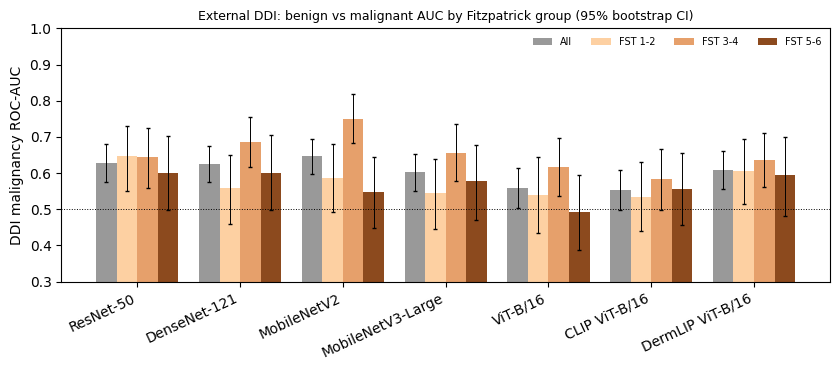

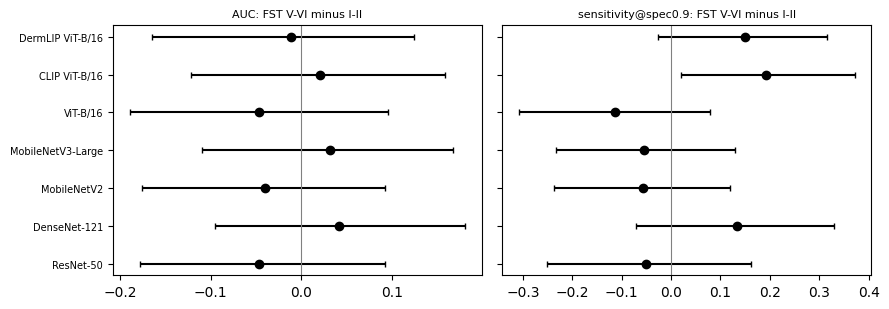

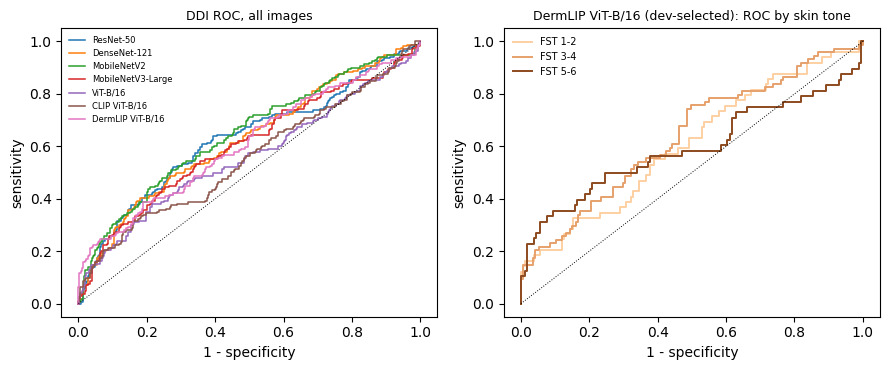


LIMITATIONS to state: (1) no patient ID in the metadata -> image-level bootstrap, intervals slightly optimistic (656 images from 570 patients); (2) DDI is binary and includes diseases outside the 8 classes, so this is a distribution-shift test, not an 8-class evaluation; (3) groups have 48-74 malignant images -> wide intervals; (4) thresholds are from ISIC+PAD validation and were not adapted to DDI; (5) CLIP/DermLIP pretraining overlap with DDI cannot be excluded; (6) results show performance differences, not their cause.
Saved to /content/drive/MyDrive/MAAI901_Group_Project/training/ddi_eval 
 ['ddi_metrics_primary.csv', 'ddi_metrics_with_AK.csv', 'ddi_skin_tone_gaps.csv', 'figures/ddi_auc_by_skin_tone.pdf', 'figures/ddi_auc_by_skin_tone.png', 'figures/ddi_roc.pdf', 'figures/ddi_roc.png', 'figures/ddi_skin_tone_gaps.pdf', 'figures/ddi_skin_tone_gaps.png', 'inference_log.json']


In [ ]:
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
B = 2000; TARGET_SPECS = [0.90, 0.95]; PRIMARY_SPEC = 0.90
MAL, MAL_AK = [CLASSES.index(c) for c in ['MEL', 'BCC', 'SCC']], [CLASSES.index(c) for c in ['MEL', 'BCC', 'SCC', 'AK']]
DEFS = {'primary (MEL+BCC+SCC)': MAL, 'sensitivity (MEL+BCC+SCC+AK)': MAL_AK}
GROUPS = ['All', '12', '34', '56']; GAPS = [('56', '12'), ('34', '12'), ('56', '34')]
DDI_DIR = BASE/'datasets'/'DDI_PRIVATE'/'raw'; DDI_OUT = TRAIN_ROOT/'ddi_eval'; SC = [f'p_{c}' for c in CLASSES]
FT = [f'{a}__finetune' for a in ARCHS]; ids = [e for e in FT if (DDI_OUT/'preds'/f'{e}.csv').exists() and (EXP_ROOT/e/'val_preds.csv').exists()]
if not ids: halt('No DDI predictions found. Run Cell 11 first.')
print('Models analysed:', [MATRIX.set_index('exp_id').model[e] for e in ids])

meta = pd.read_csv(DDI_DIR/'ddi_metadata.csv'); meta['malignant'] = meta.malignant.astype(str).str.strip().str.lower().isin(['true', '1', '1.0']); meta['skin_tone'] = meta.skin_tone.astype(int)
D = {}
mi = meta.set_index('DDI_file')
for e in ids:
    d = pd.read_csv(DDI_OUT/'preds'/f'{e}.csv'); lab_ = d.malignant.astype(str).str.strip().str.lower().isin(['true', '1', '1.0']).values
    assert set(d.DDI_file) == set(mi.index), f'{e}: DDI predictions do not cover the metadata images'
    assert (mi.loc[d.DDI_file].malignant.values == lab_).all(), f'{e}: DDI labels in the prediction file disagree with the metadata'
    assert np.allclose(d[SC].sum(1), 1, atol=1e-3), f'{e}: probabilities do not sum to 1'
    d['malignant'] = lab_; D[e] = d
base_d = D[ids[0]]; yb = base_d.malignant.values.astype(bool); tone = base_d.skin_tone.astype(int).astype(str).values
assert all((D[e].DDI_file.values == base_d.DDI_file.values).all() for e in ids), 'prediction files are not in the same image order'
cluster = pd.factorize(base_d.DDI_ID)[0]; unique_ids = base_d.DDI_ID.nunique() == len(base_d)
print('Bootstrap unit:', 'IMAGES (the metadata has no patient identifier; DDI_ID is unique per image)' if unique_ids else 'DDI_ID clusters')

def auc(y, s):
    n1 = int(y.sum()); n0 = len(y) - n1
    return (rankdata(s)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def ss(y, s, thr): return float((s[y] > thr).mean()), float((s[~y] <= thr).mean())

# Calculate thresholds using validation data
VAL = {e: pd.read_csv(EXP_ROOT/e/'val_preds.csv').set_index('image_uid').reindex(dfs['val'].image_uid) for e in ids}
THR = {}
for e in ids:
    pv = VAL[e][SC].values; yv = VAL[e].y_true.astype(int).values
    for dn, pos in DEFS.items():
        s = pv[:, pos].sum(1); isp = np.isin(yv, pos)
        for t in TARGET_SPECS: THR[(e, dn, t)] = float(np.quantile(s[~isp], t))
# Calculate AUC on the original test dataset
def dev_test_auc(e, pos):
    d = pd.read_csv(EXP_ROOT/e/'test_preds.csv').set_index('image_uid').reindex(dfs['test'].image_uid); return auc(np.isin(d.y_true.astype(int).values, pos), d[SC].values[:, pos].sum(1))

# Bootstrap samples for each skin tone group
rng = np.random.default_rng(SEED); gidx = {g: np.where(tone == g)[0] for g in GROUPS[1:]}
def draw(idx):
    cl = np.unique(cluster[idx]); mem = {c: idx[cluster[idx] == c] for c in cl}
    return np.concatenate([mem[c] for c in rng.choice(cl, len(cl), replace=True)])
boot = []
for _ in range(B):
    per = {g: draw(gidx[g]) for g in GROUPS[1:]}; per['All'] = np.concatenate([per[g] for g in GROUPS[1:]]); boot.append(per)
print('Group sizes:', {g: len(v) for g, v in gidx.items()}, '| malignant per group:', {g: int(yb[v].sum()) for g, v in gidx.items()})

def metrics_for(s, thr_by_spec, idx):
    y = yb[idx]; ss_ = s[idx]; out = {'auc': auc(y, ss_)}
    for t in TARGET_SPECS: out[f'sens{int(t*100)}'], out[f'spec{int(t*100)}'] = ss(y, ss_, thr_by_spec[t])
    return out
KEYS = ['auc'] + [f'{m}{int(t*100)}' for t in TARGET_SPECS for m in ('sens', 'spec')]
rows, R = [], {}
lab = MATRIX.set_index('exp_id')
for e in ids:
    for dn, pos in DEFS.items():
        s = D[e][SC].values[:, pos].sum(1); thr = {t: THR[(e, dn, t)] for t in TARGET_SPECS}
        reps = {g: {k: np.empty(B) for k in KEYS} for g in GROUPS}
        for b, per in enumerate(boot):
            for g in GROUPS:
                m = metrics_for(s, thr, per[g])
                for k in KEYS: reps[g][k][b] = m[k]
        R[(e, dn)] = reps
        for g in GROUPS:
            idx = np.arange(len(yb)) if g == 'All' else gidx[g]; pt = metrics_for(s, thr, idx)
            for t in TARGET_SPECS:
                k = int(t * 100); rows.append({'definition': dn, 'exp_id': e, 'model': lab.model[e], 'group': g if g == 'All' else f'FST {g[0]}-{g[1]}' if len(g) == 2 else g,
                    'n': len(idx), 'n_malignant': int(yb[idx].sum()), 'target_spec_on_dev_val': t, 'dev_val_threshold': thr[t],
                    'auc': pt['auc'], 'auc_lo': np.percentile(reps[g]['auc'], 2.5), 'auc_hi': np.percentile(reps[g]['auc'], 97.5),
                    'sensitivity': pt[f'sens{k}'], 'sens_lo': np.percentile(reps[g][f'sens{k}'], 2.5), 'sens_hi': np.percentile(reps[g][f'sens{k}'], 97.5),
                    'specificity': pt[f'spec{k}'], 'spec_lo': np.percentile(reps[g][f'spec{k}'], 2.5), 'spec_hi': np.percentile(reps[g][f'spec{k}'], 97.5),
                    'dev_test_auc_same_score': dev_test_auc(e, pos)})
T = pd.DataFrame(rows)
for dn in DEFS: save_csv(T[T.definition == dn], DDI_OUT/('ddi_metrics_primary.csv' if dn.startswith('primary') else 'ddi_metrics_with_AK.csv'))

# Compare performance between skin tone groups
gap = []
for e in ids:
    for dn in DEFS:
        reps = R[(e, dn)]
        for ga, gb in GAPS:
            for k, nm in [('auc', 'AUC'), (f'sens{int(PRIMARY_SPEC*100)}', f'sensitivity@spec{PRIMARY_SPEC}'), (f'spec{int(PRIMARY_SPEC*100)}', f'specificity@spec{PRIMARY_SPEC}')]:
                d = reps[ga][k] - reps[gb][k]
                est = T[(T.definition == dn) & (T.exp_id == e) & (T.group.isin([f'FST {ga[0]}-{ga[1]}'])) & (T.target_spec_on_dev_val == PRIMARY_SPEC)]
                est2 = T[(T.definition == dn) & (T.exp_id == e) & (T.group == f'FST {gb[0]}-{gb[1]}') & (T.target_spec_on_dev_val == PRIMARY_SPEC)]
                colname = 'auc' if k == 'auc' else ('sensitivity' if k.startswith('sens') else 'specificity')
                p = min(1.0, 2 * min(((d <= 0).sum() + 1) / (B + 1), ((d >= 0).sum() + 1) / (B + 1)))
                gap.append({'definition': dn, 'model': lab.model[e], 'exp_id': e, 'gap': f'FST {ga[0]}-{ga[1]} minus FST {gb[0]}-{gb[1]}', 'metric': nm,
                            'difference': float(est[colname].iloc[0] - est2[colname].iloc[0]), 'ci_lo': np.percentile(d, 2.5), 'ci_hi': np.percentile(d, 97.5), 'p_bootstrap': p})
GP = pd.DataFrame(gap); save_csv(GP, DDI_OUT/'ddi_skin_tone_gaps.csv')

prim = T[(T.definition.str.startswith('primary')) & (T.target_spec_on_dev_val == PRIMARY_SPEC)]
fm = lambda v, lo, hi: f'{v:.3f} [{lo:.3f}, {hi:.3f}]'
view = prim.assign(AUC=[fm(*r) for r in zip(prim.auc, prim.auc_lo, prim.auc_hi)], Sens=[fm(*r) for r in zip(prim.sensitivity, prim.sens_lo, prim.sens_hi)], Spec=[fm(*r) for r in zip(prim.specificity, prim.spec_lo, prim.spec_hi)])
print(f'\nDDI, PRIMARY definition, threshold = {PRIMARY_SPEC:.0%} specificity on development validation (95% bootstrap CI):')
print(view[view.group == 'All'][['model', 'n_malignant', 'AUC', 'Sens', 'Spec', 'dev_test_auc_same_score']].round(3).to_string(index=False))
print('\nBy skin-tone group:'); print(view[view.group != 'All'].pivot_table(index='model', columns='group', values='AUC', aggfunc='first').to_string())
g1 = GP[(GP.definition.str.startswith('primary')) & (GP.gap == 'FST 5-6 minus FST 1-2') & (GP.metric == 'AUC')]
print('\nAUC gap, FST V-VI minus FST I-II (negative = worse on darker skin):'); print(g1[['model', 'difference', 'ci_lo', 'ci_hi', 'p_bootstrap']].round(3).to_string(index=False))
print('\nWith AK counted as malignant-risk (sensitivity analysis), overall AUC:'); ak = T[(T.definition.str.startswith('sensitivity')) & (T.group == 'All') & (T.target_spec_on_dev_val == PRIMARY_SPEC)]; print(ak[['model', 'auc', 'auc_lo', 'auc_hi']].round(3).to_string(index=False))

# Plot results
OUTF = DDI_OUT/'figures'; OUTF.mkdir(exist_ok=True); order = [lab.model[e] for e in ids]; cols = {'All': '#999999', 'FST 1-2': '#fdd0a2', 'FST 3-4': '#e6a06b', 'FST 5-6': '#8c4a1e'}
fig, ax = plt.subplots(figsize=(8.5, 3.8)); w = 0.2
for j, g in enumerate(['All', 'FST 1-2', 'FST 3-4', 'FST 5-6']):
    sub = prim[prim.group == g].set_index('model').reindex(order)
    ax.bar(np.arange(len(order)) + (j - 1.5) * w, sub.auc, w, yerr=[sub.auc - sub.auc_lo, sub.auc_hi - sub.auc], capsize=1.5, color=cols[g], label=g, error_kw={'lw': 0.7})
ax.axhline(0.5, color='k', ls=':', lw=0.7); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha='right'); ax.set_ylabel('DDI malignancy ROC-AUC'); ax.set_ylim(0.3, 1)
ax.set_title('External DDI: benign vs malignant AUC by Fitzpatrick group (95% bootstrap CI)', fontsize=9); ax.legend(ncol=4, frameon=False, fontsize=7); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUTF/f'ddi_auc_by_skin_tone.{ext}', dpi=300)
plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, nm in zip(axes, ['AUC', f'sensitivity@spec{PRIMARY_SPEC}']):
    s = GP[(GP.definition.str.startswith('primary')) & (GP.gap == 'FST 5-6 minus FST 1-2') & (GP.metric == nm)].set_index('model').reindex(order)
    ax.errorbar(s.difference, range(len(order)), xerr=[s.difference - s.ci_lo, s.ci_hi - s.difference], fmt='o', color='k', capsize=2); ax.axvline(0, color='grey', lw=0.8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7); ax.set_title(f'{nm}: FST V-VI minus I-II', fontsize=8)
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUTF/f'ddi_skin_tone_gaps.{ext}', dpi=300)
plt.show(); plt.close(fig)

best = max(ids, key=lambda e: read_status(e).get('best_val_macro_f1') or 0)      # Select the best model based on validation results
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for e in ids:
    s = D[e][SC].values[:, MAL].sum(1); fpr, tpr, _ = roc_curve(yb, s); axes[0].plot(fpr, tpr, lw=1.1, label=lab.model[e])
axes[0].plot([0, 1], [0, 1], 'k:', lw=0.7); axes[0].set_title('DDI ROC, all images', fontsize=9); axes[0].legend(fontsize=6, frameon=False)
s = D[best][SC].values[:, MAL].sum(1)
for g, c in zip(GROUPS[1:], ['#fdd0a2', '#e6a06b', '#8c4a1e']):
    fpr, tpr, _ = roc_curve(yb[gidx[g]], s[gidx[g]]); axes[1].plot(fpr, tpr, color=c, lw=1.4, label=f'FST {g[0]}-{g[1]}')
axes[1].plot([0, 1], [0, 1], 'k:', lw=0.7); axes[1].set_title(f'{lab.model[best]} (dev-selected): ROC by skin tone', fontsize=9); axes[1].legend(fontsize=7, frameon=False)
for a in axes: a.set_xlabel('1 - specificity'); a.set_ylabel('sensitivity')
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUTF/f'ddi_roc.{ext}', dpi=300)
plt.show(); plt.close(fig)

print('\nLIMITATIONS to state: (1) no patient ID in the metadata -> image-level bootstrap, intervals slightly optimistic (656 images from 570 patients); (2) DDI is binary and includes diseases outside the 8 classes, so this is a distribution-shift test, not an 8-class evaluation;',
      '(3) groups have 48-74 malignant images -> wide intervals; (4) thresholds are from ISIC+PAD validation and were not adapted to DDI; (5) CLIP/DermLIP pretraining overlap with DDI cannot be excluded; (6) results show performance differences, not their cause.')
print('Saved to', DDI_OUT, '\n', sorted(str(p.relative_to(DDI_OUT)) for p in DDI_OUT.rglob('*') if p.is_file() and 'preds' not in str(p)))

## Cell 13 - ISIC and PAD Dataset Comparison

Thresholds identical to those used in the DDI analysis (no change).
{'ISIC only': (3788, 1149), 'PAD only': (341, 161), 'All development test': (4129, 1310)} <- (images, malignant)

Binary malignancy (MEL+BCC+SCC) on the development TEST split, by source (95% group-bootstrap CI; threshold = 90% specificity on dev validation):

[ISIC only]
            model                  AUC                 Sens                 Spec
        ResNet-50 0.914 [0.903, 0.925] 0.689 [0.657, 0.720] 0.922 [0.910, 0.934]
     DenseNet-121 0.909 [0.897, 0.920] 0.701 [0.671, 0.729] 0.917 [0.905, 0.928]
      MobileNetV2 0.904 [0.893, 0.915] 0.678 [0.646, 0.707] 0.910 [0.899, 0.922]
MobileNetV3-Large 0.903 [0.892, 0.914] 0.656 [0.626, 0.684] 0.921 [0.909, 0.932]
         ViT-B/16 0.906 [0.895, 0.917] 0.701 [0.671, 0.732] 0.907 [0.895, 0.919]
    CLIP ViT-B/16 0.918 [0.907, 0.928] 0.715 [0.683, 0.744] 0.918 [0.907, 0.930]
 DermLIP ViT-B/16 0.918 [0.906, 0.928] 0.745 [0.717, 0.773] 0.908 [0.895, 0.920]

[PAD only]

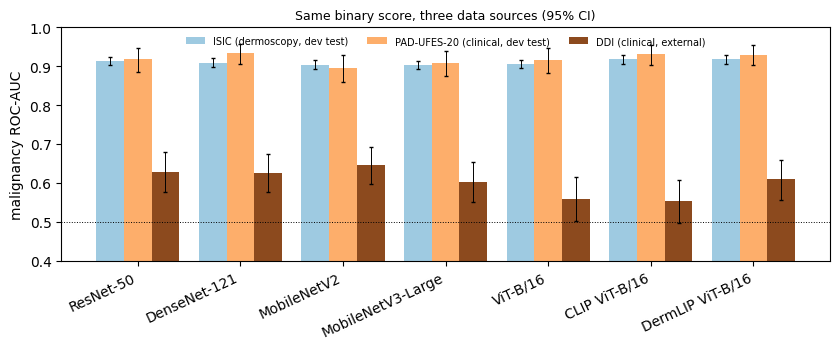

Saved to /content/drive/MyDrive/MAAI901_Group_Project/training/domain_eval


In [ ]:
from scipy.stats import rankdata
import matplotlib.pyplot as plt
B, SPEC = 2000, 0.90; MAL = [CLASSES.index(c) for c in ['MEL', 'BCC', 'SCC']]; SC = [f'p_{c}' for c in CLASSES]
OUT = TRAIN_ROOT/'domain_eval'; OUT.mkdir(parents=True, exist_ok=True); DDI_OUT = TRAIN_ROOT/'ddi_eval'
FT = [f'{a}__finetune' for a in ARCHS]; ids = [e for e in FT if (EXP_ROOT/e/'test_preds.csv').exists() and (EXP_ROOT/e/'val_preds.csv').exists()]
if not ids: halt('No saved dev predictions found.')
te = dfs['test']; src = te.source_dataset.values; yt = te.label_idx.values; lab = MATRIX.set_index('exp_id')

def aligned(e, split):
    d = pd.read_csv(EXP_ROOT/e/f'{split}_preds.csv').set_index('image_uid').reindex(dfs[split].image_uid)
    assert (d.y_true.astype(int).values == dfs[split].label_idx.values).all() and (d.source_dataset.values == dfs[split].source_dataset.values).all(), f'{e}/{split}: predictions disagree with the frozen split'
    return d[SC].values.astype(float)
PT = {e: aligned(e, 'test') for e in ids}; PV = {e: aligned(e, 'val') for e in ids}; yv = dfs['val'].label_idx.values
THR = {}
for e in ids:
    s = PV[e][:, MAL].sum(1); THR[e] = float(np.quantile(s[~np.isin(yv, MAL)], SPEC))
sv = DDI_OUT/'ddi_metrics_primary.csv'
if sv.exists():
    ref = pd.read_csv(sv); ref = ref[(ref.group == 'All') & (ref.target_spec_on_dev_val == SPEC)].set_index('exp_id').dev_val_threshold
    for e in ids:
        if e in ref.index: assert abs(ref[e] - THR[e]) < 1e-9, f'{e}: threshold differs from the one used in the DDI analysis'
    print('Thresholds identical to those used in the DDI analysis (no change).')

SUB = {'ISIC only': src == 'ISIC2019', 'PAD only': src == 'PAD_UFES_20', 'All development test': np.ones(len(te), bool)}
print({k: (int(v.sum()), int(np.isin(yt[v], MAL).sum())) for k, v in SUB.items()}, '<- (images, malignant)')
def auc(y, s):
    n1 = int(y.sum()); n0 = len(y) - n1; return (rankdata(s)[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def m8(y, pred, cls):
    cm = np.bincount(y * N_CLASSES + pred, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES); tp = np.diag(cm).astype(float); sup = cm.sum(1); pp = cm.sum(0)
    pr = np.divide(tp, pp, out=np.zeros(N_CLASSES), where=pp > 0); rc = np.divide(tp, sup, out=np.zeros(N_CLASSES), where=sup > 0); f1 = np.divide(2 * pr * rc, pr + rc, out=np.zeros(N_CLASSES), where=(pr + rc) > 0)
    return tp.sum() / cm.sum(), rc[cls].mean(), f1[cls].mean()
def metrics(e, idx, cls):
    y = yt[idx]; yb = np.isin(y, MAL); s = PT[e][idx][:, MAL].sum(1); a, ba, f1 = m8(y, PT[e][idx].argmax(1), cls)
    return {'auc': auc(yb, s), 'sens': float((s[yb] > THR[e]).mean()), 'spec': float((s[~yb] <= THR[e]).mean()), 'accuracy': a, 'balanced_acc_present': ba, 'macro_f1_present': f1}
K = ['auc', 'sens', 'spec', 'accuracy', 'balanced_acc_present', 'macro_f1_present']
rng = np.random.default_rng(SEED); rows = []
for sn, mask in SUB.items():
    idx0 = np.where(mask)[0]; cls = np.unique(yt[idx0]); gc = pd.factorize(te.group_id.values[idx0])[0]; mem = np.split(np.argsort(gc, kind='stable'), np.cumsum(np.bincount(gc))[:-1])
    boot = [idx0[np.concatenate([mem[k] for k in rng.integers(0, len(mem), len(mem))])] for _ in range(B)]       # Resample groups for all models
    for e in ids:
        pt = metrics(e, idx0, cls); rep = {k: np.empty(B) for k in K}
        for b, ix in enumerate(boot):
            m = metrics(e, ix, cls)
            for k in K: rep[k][b] = m[k]
        r = {'subset': sn, 'exp_id': e, 'model': lab.model[e], 'n': len(idx0), 'n_malignant': int(np.isin(yt[idx0], MAL).sum()), 'classes_present': len(cls), 'dev_val_threshold': THR[e]}
        for k in K: r[k] = pt[k]; r[k + '_lo'] = np.nanpercentile(rep[k], 2.5); r[k + '_hi'] = np.nanpercentile(rep[k], 97.5)
        rows.append(r)
R = pd.DataFrame(rows); save_csv(R, OUT/'isic_vs_pad_metrics.csv')
if R[['auc_lo', 'sens_lo']].isna().any().any(): print('WARNING: some subsets are too small for a bootstrap interval (NaN).')
fm = lambda r, k: f'{r[k]:.3f} [{r[k+"_lo"]:.3f}, {r[k+"_hi"]:.3f}]'
V = R.assign(AUC=R.apply(lambda r: fm(r, 'auc'), axis=1), Sens=R.apply(lambda r: fm(r, 'sens'), axis=1), Spec=R.apply(lambda r: fm(r, 'spec'), axis=1))
print('\nBinary malignancy (MEL+BCC+SCC) on the development TEST split, by source (95% group-bootstrap CI; threshold = 90% specificity on dev validation):')
for sn in SUB: print(f'\n[{sn}]'); print(V[V.subset == sn][['model', 'AUC', 'Sens', 'Spec']].to_string(index=False))
print('\n8-class (PAD has no DF/VASC, so PAD-only macro-F1 / balanced accuracy average over the classes present):')
print(R[R.subset == 'PAD only'].round(3)[['model', 'accuracy', 'balanced_acc_present', 'macro_f1_present']].to_string(index=False))

# Compare AUC scores across ISIC, PAD and DDI
cmp_ = R[R.subset.isin(['ISIC only', 'PAD only'])].pivot_table(index='model', columns='subset', values=['auc', 'auc_lo', 'auc_hi'], dropna=False)
cmp_.columns = [f'{a}_{b.split()[0].lower()}' for a, b in cmp_.columns]; cmp_ = cmp_.reset_index()
if sv.exists():
    dd = pd.read_csv(sv); dd = dd[(dd.group == 'All') & (dd.target_spec_on_dev_val == SPEC) & dd.definition.str.startswith('primary')][['model', 'auc', 'auc_lo', 'auc_hi']].rename(columns={'auc': 'auc_ddi', 'auc_lo': 'auc_lo_ddi', 'auc_hi': 'auc_hi_ddi'})
    cmp_ = cmp_.merge(dd, on='model', how='left')
save_csv(cmp_, OUT/'auc_isic_pad_ddi.csv'); print('\nAUC by data source:'); print(cmp_[[c for c in cmp_.columns if not c.startswith('auc_lo') and not c.startswith('auc_hi')]].round(3).to_string(index=False))
order = [lab.model[e] for e in ids]; fig, ax = plt.subplots(figsize=(8.5, 3.6)); w = 0.27
for j, (s, c) in enumerate([('isic', '#9ecae1'), ('pad', '#fdae6b'), ('ddi', '#8c4a1e')]):
    if f'auc_{s}' not in cmp_: continue
    sub = cmp_.set_index('model').reindex(order); ax.bar(np.arange(len(order)) + (j - 1) * w, sub[f'auc_{s}'], w, yerr=[sub[f'auc_{s}'] - sub[f'auc_lo_{s}'], sub[f'auc_hi_{s}'] - sub[f'auc_{s}']], capsize=1.5, color=c, label={'isic': 'ISIC (dermoscopy, dev test)', 'pad': 'PAD-UFES-20 (clinical, dev test)', 'ddi': 'DDI (clinical, external)'}[s], error_kw={'lw': 0.7})
ax.axhline(0.5, color='k', ls=':', lw=0.7); ax.set_ylim(0.4, 1); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, ha='right'); ax.set_ylabel('malignancy ROC-AUC')
ax.set_title('Same binary score, three data sources (95% CI)', fontsize=9); ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center'); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(OUT/f'auc_isic_pad_ddi.{ext}', dpi=300)
plt.show(); plt.close(fig); print('Saved to', OUT)

## Cell 14 - DDI Per-Disease Analysis

78 diseases; 16 with n >= 10 (cover 498 of 656 images).

Where the errors come from (DDI, threshold = 90% specificity on dev validation):
            model  false_positives                                                        top_FP_diseases  false_negatives                                                        top_FN_diseases
        ResNet-50              133 melanocytic-nevi (27); seborrheic-keratosis (16); verruca-vulgaris ...               85 mycosis-fungoides (18); squamous-cell-carcinoma-in-situ (18); basal...
     DenseNet-121              186 melanocytic-nevi (49); verruca-vulgaris (23); seborrheic-keratosis ...               78 mycosis-fungoides (20); squamous-cell-carcinoma-in-situ (14); basal...
      MobileNetV2               93 melanocytic-nevi (15); verruca-vulgaris (14); seborrheic-keratosis ...              105 mycosis-fungoides (26); squamous-cell-carcinoma-in-situ (21); basal...
MobileNetV3-Large              116 melanocytic-nevi (34); verruca-vulgaris (13); sebor

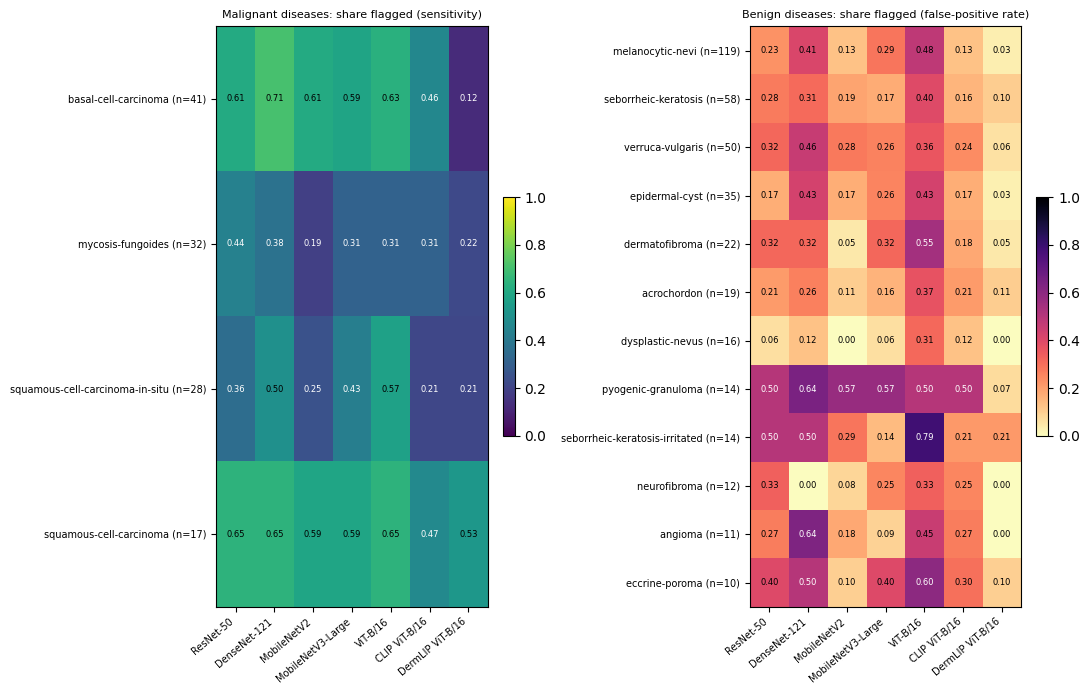


Caveats: per-disease counts are small (CIs in per_disease_metrics.csv are wide); DDI labels are binary and many diseases lie outside the 8 training classes; image-level (no patient ID); this describes where errors occur, not why.
Saved to /content/drive/MyDrive/MAAI901_Group_Project/training/ddi_eval


In [ ]:
import matplotlib.pyplot as plt
SPEC = 0.90; MAL = [CLASSES.index(c) for c in ['MEL', 'BCC', 'SCC']]; SC = [f'p_{c}' for c in CLASSES]
DDI_DIR = BASE/'datasets'/'DDI_PRIVATE'/'raw'; DDI_OUT = TRAIN_ROOT/'ddi_eval'
FT = [f'{a}__finetune' for a in ARCHS]; ids = [e for e in FT if (DDI_OUT/'preds'/f'{e}.csv').exists() and (EXP_ROOT/e/'val_preds.csv').exists()]
if not ids: halt('No DDI predictions found. Run Cell 11 first.')
lab = MATRIX.set_index('exp_id')
meta = pd.read_csv(DDI_DIR/'ddi_metadata.csv')
if 'disease' not in meta.columns: halt(f'ddi_metadata.csv has no disease column; columns: {list(meta.columns)}')
meta['malignant'] = meta.malignant.astype(str).str.strip().str.lower().isin(['true', '1', '1.0']); meta['skin_tone'] = meta.skin_tone.astype(int); meta['disease'] = meta.disease.astype(str).str.strip().str.lower()
mixed = meta.groupby('disease').malignant.nunique(); mixed = mixed[mixed > 1]
if len(mixed): print('WARNING: these diseases carry both benign and malignant labels:', list(mixed.index))
dz = meta.groupby('disease').agg(n=('DDI_file', 'size'), n_malignant=('malignant', 'sum')).sort_values('n', ascending=False); dz['label'] = np.where(dz.n_malignant == dz.n, 'malignant', np.where(dz.n_malignant == 0, 'benign', 'mixed'))
print(f'{len(dz)} diseases; {int((dz.n >= 10).sum())} with n >= 10 (cover {int(dz[dz.n >= 10].n.sum())} of {len(meta)} images).')
save_csv(pd.crosstab(meta.disease, meta.skin_tone).reindex(dz.index).reset_index(), DDI_OUT/'disease_by_skin_tone_counts.csv')

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d; return (c - h, c + h)
yv = dfs['val'].label_idx.values; mi = meta.set_index('DDI_file'); sv = DDI_OUT/'ddi_metrics_primary.csv'
ref = pd.read_csv(sv) if sv.exists() else None; rows = []
for e in ids:
    pv = pd.read_csv(EXP_ROOT/e/'val_preds.csv').set_index('image_uid').reindex(dfs['val'].image_uid)[SC].values; s_v = pv[:, MAL].sum(1); thr = float(np.quantile(s_v[~np.isin(yv, MAL)], SPEC))
    if ref is not None:
        r_ = ref[(ref.exp_id == e) & (ref.group == 'All') & (ref.target_spec_on_dev_val == SPEC) & ref.definition.str.startswith('primary')]
        if len(r_): assert abs(r_.dev_val_threshold.iloc[0] - thr) < 1e-9, f'{e}: threshold differs from the DDI analysis'
    d = pd.read_csv(DDI_OUT/'preds'/f'{e}.csv'); assert set(d.DDI_file) == set(mi.index) and np.allclose(d[SC].sum(1), 1, atol=1e-3), f'{e}: DDI prediction file inconsistent with metadata'
    d['disease'] = mi.loc[d.DDI_file].disease.values; d['mal'] = mi.loc[d.DDI_file].malignant.values; p = d[SC].values; d['score'] = p[:, MAL].sum(1); d['flag'] = d.score > thr; d['top'] = [CLASSES[k] for k in p.argmax(1)]
    for dis, g in d.groupby('disease'):
        n = len(g); k = int(g.flag.sum()); lo, hi = wilson(k, n); lab_ = 'malignant' if g.mal.all() else 'benign' if (~g.mal).all() else 'mixed'
        vc = g.top.value_counts(); rows.append({'exp_id': e, 'model': lab.model[e], 'disease': dis, 'ddi_label': lab_, 'n': n, 'flagged_malignant': k, 'flag_rate': k / n, 'flag_lo': lo, 'flag_hi': hi,
            'rate_means': 'sensitivity' if lab_ == 'malignant' else 'false-positive rate' if lab_ == 'benign' else 'mixed', 'mean_malignancy_score': g.score.mean(), 'modal_8class_prediction': vc.index[0], 'modal_share': vc.iloc[0] / n, 'threshold': thr})
PD_ = pd.DataFrame(rows).sort_values(['model', 'n'], ascending=[True, False]); save_csv(PD_, DDI_OUT/'per_disease_metrics.csv')

# Identify diseases with the most errors
err = []
for e in ids:
    g = PD_[PD_.exp_id == e].copy(); g['FP'] = np.where(g.ddi_label == 'benign', g.flagged_malignant, 0); g['FN'] = np.where(g.ddi_label == 'malignant', g.n - g.flagged_malignant, 0)
    tot_fp, tot_fn = int(g.FP.sum()), int(g.FN.sum()); top_fp = g.sort_values('FP', ascending=False).head(3); top_fn = g.sort_values('FN', ascending=False).head(3)
    err.append({'model': lab.model[e], 'false_positives': tot_fp, 'top_FP_diseases': '; '.join(f'{r.disease} ({int(r.FP)})' for r in top_fp.itertuples() if r.FP > 0), 'false_negatives': tot_fn, 'top_FN_diseases': '; '.join(f'{r.disease} ({int(r.FN)})' for r in top_fn.itertuples() if r.FN > 0)})
ER = pd.DataFrame(err); save_csv(ER, DDI_OUT/'per_disease_top_errors.csv'); print('\nWhere the errors come from (DDI, threshold = 90% specificity on dev validation):'); print(ER.to_string(index=False, max_colwidth=70))
print('\nDermLIP / best-in-dev model per-disease detail (diseases with n >= 10; flag rate = share predicted malignant):')
best = max(ids, key=lambda e: read_status(e).get('best_val_macro_f1') or 0)
print(PD_[(PD_.exp_id == best) & (PD_.n >= 10)].round(3)[['disease', 'ddi_label', 'n', 'flag_rate', 'flag_lo', 'flag_hi', 'modal_8class_prediction', 'modal_share']].to_string(index=False))

# Compare results across different diseases
big = list(dz[dz.n >= 10].index); order = [lab.model[e] for e in ids]; fig, axes = plt.subplots(1, 2, figsize=(11, 0.34 * max(len(big), 4) + 1.6), gridspec_kw={'width_ratios': [1, 1]})
for ax, lbl, ttl in zip(axes, ['malignant', 'benign'], ['Malignant diseases: share flagged (sensitivity)', 'Benign diseases: share flagged (false-positive rate)']):
    dis = [d_ for d_ in big if dz.label[d_] == lbl]
    if not dis: ax.axis('off'); continue
    M = np.array([[PD_[(PD_.model == m) & (PD_.disease == d_)].flag_rate.iloc[0] for m in order] for d_ in dis]); im = ax.imshow(M, vmin=0, vmax=1, cmap='viridis' if lbl == 'malignant' else 'magma_r', aspect='auto')
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=40, ha='right', fontsize=7); ax.set_yticks(range(len(dis))); ax.set_yticklabels([f'{d_} (n={int(dz.n[d_])})' for d_ in dis], fontsize=7)
    for i in range(len(dis)):
        for j in range(len(order)): ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if (M[i, j] < 0.5) == (lbl == 'malignant') else 'black')
    ax.set_title(ttl, fontsize=8); fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
(DDI_OUT/'figures').mkdir(exist_ok=True)
for ext in ('png', 'pdf'): fig.savefig(DDI_OUT/'figures'/f'per_disease_flag_rate.{ext}', dpi=300)
plt.show(); plt.close(fig)
print('\nCaveats: per-disease counts are small (CIs in per_disease_metrics.csv are wide); DDI labels are binary and many diseases lie outside the 8 training classes; image-level (no patient ID); this describes where errors occur, not why.')
print('Saved to', DDI_OUT)